H2: ***Projects that integrate AI as a product feature exhibit different code quality outcomes than projects that do not***

%pip install matplotlib seaborn pandas

In [42]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [43]:
BASE_DIR = Path().resolve().parent.parent / "output_files"
aicp_csv_path = BASE_DIR / "ai_component_profile.csv"
sqp_csv_path = BASE_DIR / "software_quality_profile.csv"

aicp_df = pd.read_csv(aicp_csv_path)
sqp_df = pd.read_csv(sqp_csv_path)

print(sqp_df.columns)
print(sqp_df.shape)

cols = sqp_df.columns
for col in cols:
    print(f"Column: {col}, Unique Values: {sqp_df[col].nunique()}")

Index(['repository_id', 'snapshot_commit', 'date', 'bugs', 'classes',
       'code_smells', 'cognitive_complexity', 'comment_lines',
       'comment_lines_density', 'complexity', 'coverage', 'duplicated_blocks',
       'duplicated_files', 'duplicated_lines', 'duplicated_lines_density',
       'files', 'functions', 'lines', 'lines_to_cover', 'ncloc', 'open_issues',
       'reliability_rating', 'reliability_remediation_effort',
       'security_hotspots', 'security_rating', 'security_remediation_effort',
       'security_review_rating', 'sqale_debt_ratio', 'sqale_index',
       'sqale_rating', 'statements', 'tests', 'uncovered_lines', 'violations',
       'vulnerabilities', 'n_blocker', 'n_critical', 'n_major', 'n_minor',
       'n_info', 'n_security', 'n_reliability', 'n_maintainability',
       'n_consistent', 'n_intentional', 'n_adaptable', 'n_responsible',
       'total_issues_per_kloc', 'critical_plus_blocker_ratio', 'major_ratio',
       'minor_ratio', 'info_ratio', 'security_ratio

In [44]:
quality_metrics = [
        "bugs", "classes", "code_smells", 
        "cognitive_complexity", "comment_lines", "comment_lines_density", 
        "complexity", "coverage", "duplicated_blocks", "duplicated_files", 
        "duplicated_lines", "duplicated_lines_density", "files", "functions", 
        "lines", "lines_to_cover", "ncloc", "open_issues", "reliability_rating", 
        "reliability_remediation_effort", "security_hotspots", "security_rating", 
        "security_remediation_effort", "security_review_rating", "sqale_debt_ratio", 
        "sqale_index", "sqale_rating", "statements", "tests", "uncovered_lines", 
        "violations", "vulnerabilities", "n_blocker", "n_critical", "n_major", 
        "n_minor", "n_info", "n_security", "n_reliability", "n_maintainability", 
        "n_consistent", "n_intentional", "n_adaptable", "n_responsible", 
        "total_issues_per_kloc", "critical_plus_blocker_ratio", "major_ratio", 
        "minor_ratio", "info_ratio", "security_ratio", "reliability_ratio", 
        "maintainability_ratio"
    ]

METRIC_LABELS = {
    "bugs":                     "Bugs",
    "code_smells":              "Code Smells",
    "cognitive_complexity":     "Cognitive Complexity",
    "complexity":               "Cyclomatic Complexity",
    "duplicated_lines_density": "Duplication Density (%)",
    "vulnerabilities":          "Vulnerabilities",
    "sqale_debt_ratio":         "Technical Debt Ratio (%)",
    "total_issues_per_kloc":    "Issues per kLoC",
    "classes":                  "Classes",
    "comment_lines":            "Comment Lines",
    "comment_lines_density":    "Comment Lines Density (%)",
    "files":                    "Files",
    "functions":                "Functions",
    "lines":                    "Lines",
    "lines_to_cover":           "Lines to Cover",
    "ncloc":                    "Non-Comment Lines of Code",
    "open_issues":              "Open Issues",
    "reliability_rating":       "Reliability Rating",
    "reliability_remediation_effort": "Reliability Remediation Effort",
    "security_hotspots":        "Security Hotspots",
    "security_rating":         "Security Rating",
    "security_remediation_effort": "Security Remediation Effort",
    "security_review_rating":   "Security Review Rating",
    "sqale_index":             "Technical Debt (days)",
    "sqale_rating":            "Technical Debt Rating",
    "statements":              "Statements",
    "tests":                   "Tests",
    "uncovered_lines":         "Uncovered Lines",
    "violations":              "Violations",
    "n_blocker":               "Blocker Issues",
    "n_critical":              "Critical Issues",
    "n_major":                 "Major Issues",
    "n_minor":                 "Minor Issues",
    "n_info":                  "Info Issues",
    "n_security":              "Security Issues",
    "n_reliability":           "Reliability Issues",
    "n_maintainability":       "Maintainability Issues",
    "n_consistent":            "Consistent Issues",
    "n_intentional":           "Intentional Issues",
    "n_adaptable":            "Adaptable Issues",
    "n_responsible":          "Responsible Issues",
    "critical_plus_blocker_ratio": "Critical + Blocker Issues Ratio",
    "major_ratio":            "Major Issues Ratio (%)",
    "minor_ratio":            "Minor Issues Ratio (%)",
    "info_ratio":             "Info Issues Ratio (%)",
    "security_ratio":         "Security Issues Ratio (%)",
    "reliability_ratio":      "Reliability Issues Ratio (%)",
    "maintainability_ratio":  "Maintainability Issues Ratio (%)",
}

additional_metrics = [
    "repository_id", "snapshot_commit", "date"
]

df = pd.merge(
    aicp_df[["repository_id", "has_ai_component", "ai_component_count"]],
    sqp_df[quality_metrics + additional_metrics],
    on=["repository_id"],
    how="inner",
    suffixes=("_aiup", "_sqp")
)

df["date"] = pd.to_datetime(df["date"], utc=True)
df_sorted = df.sort_values(["repository_id", "date"])
df = (
    df_sorted
    .groupby("repository_id")
    .tail(1)
    .reset_index(drop=True)
)

print(df.shape)

for i in range(6):
    count = (df["ai_component_count"] == i).sum()
    print(f"Projects with {i} AI components: {count}")
    
bigboy_df = df.copy()

(91, 57)
Projects with 0 AI components: 75
Projects with 1 AI components: 8
Projects with 2 AI components: 6
Projects with 3 AI components: 2
Projects with 4 AI components: 0
Projects with 5 AI components: 0


In [45]:
time_df = bigboy_df.copy()
time_df["repo_year"] = time_df["repository_id"].str[:4].astype(int)

for year in range(2017, 2026):
    count = ((time_df["repo_year"] == year) & 
             (time_df["has_ai_component"] == True)).sum()
    print(f"Projects with AI components in {year}: {count}")

average_ai_components = time_df["ai_component_count"].mean()
print(f"Average number of AI components per project: {average_ai_components:.2f}")

Projects with AI components in 2017: 0
Projects with AI components in 2018: 0
Projects with AI components in 2019: 2
Projects with AI components in 2020: 2
Projects with AI components in 2021: 1
Projects with AI components in 2022: 3
Projects with AI components in 2023: 2
Projects with AI components in 2024: 3
Projects with AI components in 2025: 3
Average number of AI components per project: 0.29


In [46]:
projects_with_ai = df[df["has_ai_component"] == True]
projects_without_ai = df[df["has_ai_component"] == False]

project_ai_count_over_1 = df[df["ai_component_count"] >= 1]
project_ai_count_under_or_equal_1 = df[df["ai_component_count"] < 1]

print(f"Projects with AI components: {len(projects_with_ai)}")
print(f"Projects without AI components: {len(projects_without_ai)}")
print(f"Projects with more than 1 AI component: {len(project_ai_count_over_1)}")
print   (f"Projects with 1 or fewer AI components: {len(project_ai_count_under_or_equal_1)}")

Projects with AI components: 16
Projects without AI components: 75
Projects with more than 1 AI component: 16
Projects with 1 or fewer AI components: 75


In [47]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

# ------------------------------------------------
# Metrics to evaluate
# ------------------------------------------------
def analyze_h2_ai_product_vs_dev(df, alpha=0.05):
    repo_df = df.copy()
    
    rows = []
    incosistency_table_rows = []
    
    for m in quality_metrics:

        quality_ai_product     = repo_df[repo_df["has_ai_component"] == True][m].dropna()
        quality_no_ai_product  = repo_df[repo_df["has_ai_component"] == False][m].dropna()

        if len(quality_ai_product) < 5 or len(quality_no_ai_product) < 5:
            continue

        # Shapiro-Wilk normality test per group
        _, shapiro_p_quality_ai_product    = stats.shapiro(quality_ai_product)    if len(quality_ai_product)    >= 3 else (None, None)
        _, shapiro_p_quality_no_ai_product = stats.shapiro(quality_no_ai_product) if len(quality_no_ai_product) >= 3 else (None, None)
        is_normally_distributed = shapiro_p_quality_ai_product > 0.05 and shapiro_p_quality_no_ai_product > 0.05

        # Mann-Whitney U: quality ~ ai_product_project
        n1 = quality_ai_product
        n2 = quality_no_ai_product

        mw_u_quality_ai_product,   mw_p   = stats.mannwhitneyu(n1, n2, alternative='two-sided')
        mw_u_quality_no_ai_product    = len(n1) * len(n2) - mw_u_quality_ai_product
        min_u = min(mw_u_quality_ai_product, mw_u_quality_no_ai_product)
        r_mw = 1 - (2 * min_u) / (len(n1) * len(n2))        
        
        # Spearman r: quality ~ ai_component_count (continuous)
        corr_df_quality_ai_count = repo_df[["ai_component_count", m]].dropna()

        if len(corr_df_quality_ai_count) >= 3:
            spearman_r_quality_ai_count, spearman_p_quality_ai_count = stats.spearmanr(
                corr_df_quality_ai_count["ai_component_count"],
                corr_df_quality_ai_count[m]
            )
        else:
            spearman_r_quality_ai_count = spearman_p_quality_ai_count = np.nan
        
        rows.append({
            "metric":                           m,
            "mean_quality(ai_product)":         round(quality_ai_product.mean(),    3),
            "median_quality(ai_product)":       round(quality_ai_product.median(),  3),
            "mean_quality(no_ai_product)":      round(quality_no_ai_product.mean(),   3),
            "median_quality(no_ai_product)":    round(quality_no_ai_product.median(), 3),
            "U(quality|ai_product)":            round(mw_u_quality_ai_product, 1),
            "U(quality|no_ai_product)":         round(mw_u_quality_no_ai_product, 1),
            "p_mw(quality|ai_product)":         round(mw_p, 4),
            "r_mw(contribution|ai_group)":      round(r_mw, 3),
            "r_spearman(quality~ai_count)":     round(spearman_r_quality_ai_count,  3),
            "p_spearman(quality~ai_count)":     round(spearman_p_quality_ai_count,  4),
            "Normal?":                          "Yes" if is_normally_distributed else "No",
        })
        
        if(mw_p < 0.1):
            # Median (AI), Median (No AI), Max (AI), Max (No AI), and rMWr_{MW} rMW
            incosistency_table_rows.append({
                "metric": m,
                "median_ai_product": round(quality_ai_product.median(), 3),
                "median_no_ai_product": round(quality_no_ai_product.median(), 3),
                "max_ai_product": round(quality_ai_product.max(), 3),
                "max_no_ai_product": round(quality_no_ai_product.max(), 3),
                "std_dev_ai_product": round(quality_ai_product.std(), 3),
                "std_dev_no_ai_product": round(quality_no_ai_product.std(), 3),
                "q3_ai_product": round(quality_ai_product.quantile(0.75), 3),
                "q3_no_ai_product": round(quality_no_ai_product.quantile(0.75), 3),
                "r_mw": round(1 - (2 * mw_u_quality_ai_product) / (len(quality_ai_product) * len(quality_no_ai_product)), 3)
            })
        
    stats_table_quality_by_ai_product = pd.DataFrame(rows)

    # print("\nGROUP COMPARISON STATISTICS")
    # display(stats_table_quality_by_ai_product)

    return {
        "repo_df":              repo_df,
        "mannwhitney_results":  stats_table_quality_by_ai_product,
        "inconsistency_results": pd.DataFrame(incosistency_table_rows)
    }


# Run analysis
h2_results = analyze_h2_ai_product_vs_dev(df)

/Users/magnus/iCloud Drive (Archive)/NTNU/Semester 10/TDT4900/pgs_v2/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)
/var/folders/_t/r4r1x6jd1c5dgbwllqhbsyrw0000gn/T/ipykernel_92368/1932080532.py:44: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_r_quality_ai_count, spearman_p_quality_ai_count = stats.spearmanr(
/Users/magnus/iCloud Drive (Archive)/NTNU/Semester 10/TDT4900/pgs_v2/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)


In [48]:
print(len(sqp_df.columns))

60


In [49]:
inconsistency_results = h2_results["inconsistency_results"]
print("Inconsistencies found in metrics:", len(inconsistency_results))
print(inconsistency_results.to_latex(index=False, float_format="%.3f"))
display(inconsistency_results)  

Inconsistencies found in metrics: 11
\begin{tabular}{lrrrrrrrrr}
\toprule
metric & median_ai_product & median_no_ai_product & max_ai_product & max_no_ai_product & std_dev_ai_product & std_dev_no_ai_product & q3_ai_product & q3_no_ai_product & r_mw \\
\midrule
classes & 16.000 & 6.000 & 158.000 & 378.000 & 53.223 & 59.096 & 49.250 & 26.000 & -0.275 \\
cognitive_complexity & 252.000 & 152.000 & 2314.000 & 73461.000 & 573.379 & 12659.334 & 459.500 & 372.500 & -0.275 \\
comment_lines & 291.500 & 180.000 & 3069.000 & 52507.000 & 1092.771 & 6216.700 & 826.750 & 348.000 & -0.361 \\
comment_lines_density & 9.750 & 6.800 & 26.700 & 35.200 & 7.892 & 8.347 & 19.125 & 10.550 & -0.357 \\
lines_to_cover & 1200.000 & 827.000 & 8606.000 & 71899.000 & 2248.883 & 10939.020 & 2326.500 & 1475.500 & -0.269 \\
reliability_rating & 3.500 & 3.000 & 5.000 & 5.000 & 1.500 & 1.470 & 5.000 & 4.000 & -0.258 \\
security_hotspots & 8.000 & 3.000 & 31.000 & 86.000 & 8.716 & 15.876 & 11.250 & 8.000 & -0.353 \\
stateme

,metric,median_ai_product,median_no_ai_product,max_ai_product,max_no_ai_product,std_dev_ai_product,std_dev_no_ai_product,q3_ai_product,q3_no_ai_product,r_mw
0,classes,16.000,6.000,158.0,378.0,53.223,59.096,49.250,26.000,-0.275
1,cognitive_complexity,252.000,152.000,2314.0,73461.0,573.379,12659.334,459.500,372.500,-0.275
2,comment_lines,291.500,180.000,3069.0,52507.0,1092.771,6216.700,826.750,348.000,-0.361
3,comment_lines_density,9.750,6.800,26.7,35.2,7.892,8.347,19.125,10.550,-0.357
4,lines_to_cover,1200.000,827.000,8606.0,71899.0,2248.883,10939.020,2326.500,1475.500,-0.269
5,reliability_rating,3.500,3.000,5.0,5.0,1.500,1.470,5.000,4.000,-0.258
6,security_hotspots,8.000,3.000,31.0,86.0,8.716,15.876,11.250,8.000,-0.353
7,statements,1255.000,844.000,8954.0,65666.0,2366.290,10700.767,2532.250,1510.000,-0.317
8,uncovered_lines,1200.000,827.000,8606.0,71899.0,2248.883,10939.020,2326.500,1475.500,-0.269
9,n_critical,7.500,4.000,67.0,10290.0,17.029,1956.760,15.500,12.000,-0.300


In [50]:
import math

def df_to_latex(df, title, label, max_cols=6, float_format="%.4f", keep_in_all_tables=[]):
    """
    Split a dataframe into multiple LaTeX tables so each table contains
    at most `max_cols` columns.

    Parameters
    ----------
    df : pandas.DataFrame
    title : str
        Base caption for the tables.
    label : str
        Base LaTeX label.
    max_cols : int
        Maximum number of columns per table.
    float_format : str
        Float formatting for LaTeX output.
    """

    cols = list(df.columns)
    n_tables = math.ceil(len(cols) / max_cols)

    for i in range(n_tables):
        start = i * max_cols
        end = start + max_cols
        sub_cols = cols[start:end]

        sub_cols = keep_in_all_tables + [c for c in sub_cols if c not in keep_in_all_tables]
        sub_df = df[sub_cols].copy()

        # Clean column names
        sub_df.columns = [c.replace("_", r"\_") for c in sub_df.columns]

        print(f"% Table {i+1}")
        print(
            sub_df.to_latex(
                index=False,
                float_format=float_format,
                escape=False,   # required so LaTeX keeps the manual escapes
                caption=f"{title} ({i+1}/{n_tables})",
                label=f"{label}_{i+1}"
            )
        )

In [51]:
repo_df = h2_results["repo_df"]
stats_table = h2_results["mannwhitney_results"]
#  "repo_df": repo_df,
# "descriptive_stats": desc_table,
# "mannwhitney_results": stats_table,

codes, _ = pd.factorize(repo_df["repository_id"])
repo_df["repository_id"] = "repository_" + (codes + 1).astype(str)

stats_table = stats_table.map(
    lambda x: x.replace("_", r"\_") if isinstance(x, str) else x
)

df_to_latex(stats_table, "Mann-Whitney t-test scores across the two project groups", "tab:mann-whiteney_for_ai_components", keep_in_all_tables=["metric"])

% Table 1
\begin{table}
\caption{Mann-Whitney t-test scores across the two project groups (1/2)}
\label{tab:mann-whiteney_for_ai_components_1}
\begin{tabular}{lrrrrr}
\toprule
metric & mean\_quality(ai\_product) & median\_quality(ai\_product) & mean\_quality(no\_ai\_product) & median\_quality(no\_ai\_product) & U(quality|ai\_product) \\
\midrule
bugs & 6.5000 & 2.5000 & 656.2670 & 3.0000 & 605.0000 \\
classes & 40.2500 & 16.0000 & 27.5350 & 6.0000 & 724.0000 \\
code\_smells & 93.3120 & 80.5000 & 2157.6270 & 57.0000 & 633.5000 \\
cognitive\_complexity & 467.6250 & 252.0000 & 2753.6480 & 152.0000 & 724.0000 \\
comment\_lines & 843.5000 & 291.5000 & 1268.9730 & 180.0000 & 816.5000 \\
comment\_lines\_density & 12.9250 & 9.7500 & 8.5720 & 6.8000 & 814.5000 \\
complexity & 641.0000 & 400.5000 & 1392.2110 & 377.0000 & 633.5000 \\
coverage & 0.0000 & 0.0000 & 0.0000 & 0.0000 & 568.0000 \\
duplicated\_blocks & 8.3120 & 2.0000 & 23.5730 & 2.0000 & 612.5000 \\
duplicated\_files & 5.2500 & 2.0000 

In [52]:
df = h2_results["mannwhitney_results"]
significant_columns = stats_table[stats_table["p_mw(quality|ai_product)"] < 0.05]["metric"].tolist()
all_columns = stats_table["metric"].tolist()

print("Significant columns:", len(significant_columns))
print("All columns:", len(all_columns))
print("All columns:", all_columns)

Significant columns: 5
All columns: 51
All columns: ['bugs', 'classes', 'code\\_smells', 'cognitive\\_complexity', 'comment\\_lines', 'comment\\_lines\\_density', 'complexity', 'coverage', 'duplicated\\_blocks', 'duplicated\\_files', 'duplicated\\_lines', 'duplicated\\_lines\\_density', 'files', 'functions', 'lines', 'lines\\_to\\_cover', 'ncloc', 'open\\_issues', 'reliability\\_rating', 'reliability\\_remediation\\_effort', 'security\\_hotspots', 'security\\_rating', 'security\\_remediation\\_effort', 'security\\_review\\_rating', 'sqale\\_debt\\_ratio', 'sqale\\_index', 'sqale\\_rating', 'statements', 'uncovered\\_lines', 'violations', 'vulnerabilities', 'n\\_blocker', 'n\\_critical', 'n\\_major', 'n\\_minor', 'n\\_info', 'n\\_security', 'n\\_reliability', 'n\\_maintainability', 'n\\_consistent', 'n\\_intentional', 'n\\_adaptable', 'n\\_responsible', 'total\\_issues\\_per\\_kloc', 'critical\\_plus\\_blocker\\_ratio', 'major\\_ratio', 'minor\\_ratio', 'info\\_ratio', 'security\\_ratio

In [53]:
# ── Universal colour palette ──────────────────────────────────────────────────
# All colours tested for mutual harmony and sufficient contrast on white/light bg

# Group / category colours
C_AI        = "#2563EB"   # blue        – AI-product group
C_DEV       = "#575B64"   # slate grey  – no AI-product group
C_ORANGE    = "#EA6C00"   # orange      – third category / accent
C_GREEN     = "#0F8C4A"   # green       – fourth category
C_RED       = "#CC1F1F"   # red         – fifth category
C_PURPLE    = "#6D28D9"   # violet      – sixth category
C_TEAL      = "#0891B2"   # teal        – seventh category

# A ready-made ordered list for cycling through groups
CATEGORY_COLORS = [C_AI, C_ORANGE, C_GREEN, C_RED, C_PURPLE, C_TEAL, C_DEV]

# Significance / annotation colours
C_SIG       = "#0F8C4A"   # green  – statistically significant  (matches C_GREEN)
C_TREND     = "#EA6C00"   # amber  – trending                   (matches C_ORANGE)
C_NS        = "#BFC8D7"   # light grey – not significant

# Direction colours (right-panel bars)
C_POS       = "#2563EB"   # blue – AI group higher              (matches C_AI)
C_NEG       = "#CC1F1F"   # red  – no-AI group higher           (matches C_RED)

# Text colours
C_TEXT      = "#111827"   # near-black – significant rows / primary labels
C_TEXT_NS   = "#6B7280"   # mid grey   – non-significant rows
C_TEXT_SOFT = "#9CA3AF"   # light grey – annotations / secondary labels

# Row / background shading
C_ROW_SIG   = "#F0FDF4"   # very light green – significant row highlight
C_ROW_TREND = "#FFF7ED"   # very light amber – trending row highlight
C_ROW_ALT   = "#F9FAFB"   # off-white        – alternating row stripe
C_ROW       = "#FFFFFF"   # white            – default row
C_ROW_SHADING = "#F9FAFB"  # light grey for alternating row shading

# Hatch patterns paired with CATEGORY_COLORS for B&W printing
CATEGORY_HATCHES = ["", "///", "...", "xxx", "\\\\\\", "|||", "+++"]

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D

def _stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    if p < 0.10:  return "†"
    return ""
 
def _sig_color(p):
    if p < 0.05:  return C_SIG
    if p < 0.10:  return C_TREND
    return C_NS
 
def _label(m):
    return METRIC_LABELS.get(m, m.replace("_", " ").title())
 
def visualize_mw_results(df, alpha=0.05, measure="median", save_path=None):
    if(measure not in ["median", "mean"]):
        raise ValueError("Measure must be 'median' or 'mean'")
    
    df = df.copy().sort_values("p_mw(quality|ai_product)", ascending=False).reset_index(drop=True)
    N  = len(df)
    y  = np.arange(N)

    if(measure == "mean"):
          df["pct_diff"] = (
            (df["mean_quality(ai_product)"] - df["mean_quality(no_ai_product)"])
            / df["mean_quality(no_ai_product)"].abs().replace(0, np.nan) * 100
        )
  
    if(measure == "median"):
        df["pct_diff"] = (
            (df["median_quality(ai_product)"] - df["median_quality(no_ai_product)"])
            / df["median_quality(no_ai_product)"].abs().replace(0, np.nan) * 100
        )

    fig, (ax_bar, ax_pct) = plt.subplots(
        1, 2, figsize=(13, max(4.5, N * 0.7 + 2.0)),
        gridspec_kw={"width_ratios": [2, 1.2], "wspace": 0.06}, dpi=300,
    )
    fig.subplots_adjust(left=0.26, right=0.97, top=0.91, bottom=0.13)

    
    # ── Row shading ───────────────────────────────────────────────────────────
    for ax in (ax_bar, ax_pct):
        for i in range(N):
            p = df.loc[i, "p_mw(quality|ai_product)"]
            bg = C_ROW_SHADING if p < alpha else (C_ROW if p < 0.10 else None)
            if i % 2 == 0 and bg is None:
                bg = C_ROW
            if bg:
                ax.axhspan(i - 0.5, i + 0.5, color=bg, zorder=0)
 
    # ════════════════════════════════════════════════════════════════════════
    # LEFT PANEL — side-by-side horizontal bar chart of raw medians
    # ════════════════════════════════════════════════════════════════════════
    bar_h = 0.35

    # Normalise per metric so bars are comparable across metrics
    for i, row in df.iterrows():
        if measure == "median":
            m_ai  = row["median_quality(ai_product)"]
            m_dev = row["median_quality(no_ai_product)"]
        else:  # measure == "mean"
            m_ai  = row["mean_quality(ai_product)"]
            m_dev = row["mean_quality(no_ai_product)"]

        scale = max(abs(m_ai), abs(m_dev), 1e-9)

        p   = row["p_mw(quality|ai_product)"]
        r = row["r_mw(contribution|ai_group)"]
        fad = 1.0 if p < alpha else 0.50
        sc  = _sig_color(p)
        
        # No-AI bar (lower slot)
        ax_bar.barh(i - bar_h / 2, m_dev / scale, height=bar_h,
                    color=C_TEAL, alpha=fad, linewidth=0, zorder=2, hatch=CATEGORY_HATCHES[1])
        # AI bar (upper slot)
        ax_bar.barh(i + bar_h / 2, m_ai  / scale, height=bar_h,
                    color=C_ORANGE,  alpha=fad, linewidth=0, zorder=2, hatch=CATEGORY_HATCHES[0])

        # Raw value labels
        ax_bar.text(m_dev / scale + 0.02, i - bar_h / 2,
                    f"{m_dev:.3g}", va="center", ha="left",
                    fontsize=10, color=C_TEAL, alpha=fad)
        ax_bar.text(m_ai  / scale + 0.02, i + bar_h / 2,
                    f"{m_ai:.3g}",  va="center", ha="left",
                    fontsize=10, color=C_ORANGE,  alpha=fad)

       # Significance annotation
        stars = _stars(p)
        p_val = f"{p:.3f}" if p >= 0.001 else "< .001"
        p_str = f"$p_{{MW}} = {p_val}$"
        r_str = f"$r_{{MW}} = {r:.3f}$"
        
        label = f"{stars} {p_str}\n{r_str}" if stars else f"{p_str}\n{r_str}"
        
        ax_bar.text(1.32, i, label,
                    va="center", ha="left",
                    fontsize=12,
                    fontweight="bold" if p < alpha else "normal",
                    color=sc,
                    usetex=False)
        
        # Metric label
        ax_bar.text(-0.04, i, _label(row["metric"]),
                    va="center", ha="right", fontsize=14,
                    color=C_TEXT if p < alpha else C_TEXT_NS)
        
    # Column headers
    if(measure == "median"):
        ax_bar.text(0.5, N - 0.1, "Normalised median (per metric)",
                    va="bottom", ha="center", fontsize=14, color=C_TEXT)
    if(measure == "mean"):
        ax_bar.text(0.5, N - 0.1, "Normalised mean (per metric)",
                    va="bottom", ha="center", fontsize=14, color=C_TEXT)
    ax_bar.text(1.12, N - 0.1, r"Significance ($p_{MW} < .10$)",
                va="bottom", ha="left",  fontsize=14, color=C_TEXT)

    ax_bar.axvline(0, color=C_TEXT, lw=0.8, linestyle="--", zorder=3)
    ax_bar.set_xlim(-0.05, 1.85)
    ax_bar.set_ylim(-0.6, N - 0.1)
    ax_bar.axis("off")

    # ════════════════════════════════════════════════════════════════════════
    # RIGHT PANEL — % median difference (unchanged)
    # ════════════════════════════════════════════════════════════════════════
    for i, row in df.iterrows():
        p   = row["p_mw(quality|ai_product)"]
        pct = row["pct_diff"]
        if pd.isna(pct):
            continue

        col = C_POS if pct >= 0 else C_NEG
        fad = 1.0 if p < alpha else 0.50

        ax_pct.barh(i, pct, height=0.5,
                    color=col, alpha=fad,
                    linewidth=0.5, edgecolor=col, zorder=2)

        offset = 1.0 if pct >= 0 else -1.0
        ax_pct.text(pct + offset, i,
                    f"{pct:+.1f}%",
                    va="center", ha="left" if pct >= 0 else "right",
                    fontsize=14, color=col, alpha=fad)

    ax_pct.axvline(0, color=C_TEXT, lw=0.9, linestyle="--", zorder=3)
    xlim = max(abs(df["pct_diff"].dropna()).max() * 1.5, 15)
    ax_pct.set_xlim(-xlim, xlim)
    ax_pct.set_ylim(-0.6, N - 0.1)
    ax_pct.set_yticks(y)
    ax_pct.set_yticklabels([])
    
    if(measure == "median"):
        ax_pct.set_xlabel("% difference in median\n(AI-product - No AI-product)", fontsize=14)
    if(measure == "mean"):
        ax_pct.set_xlabel("% difference in mean\n(AI-product - No AI-product)", fontsize=14)
        
    ax_pct.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0f}%"))
    ax_pct.spines["top"].set_visible(False)
    ax_pct.spines["right"].set_visible(False)
    ax_pct.spines["left"].set_visible(False)
    ax_pct.tick_params(left=False)

    # ── Legend ────────────────────────────────────────────────────────────────
    handles = [
        mpatches.Patch(facecolor=C_ORANGE, edgecolor=C_TEXT, label="AI-product group"),
        mpatches.Patch(facecolor=C_TEAL,   edgecolor=C_TEXT, hatch="////", linewidth=0.5, label="No AI-product group"),
        mpatches.Patch(facecolor=C_POS,    label="AI-product higher (right panel)"),
        mpatches.Patch(facecolor=C_NEG,    label="No AI-product higher (right panel)"),
    ]
        
    fig.legend(handles=handles, loc="lower center", ncol=2,
               fontsize=14, 
               edgecolor=C_TEXT_NS, bbox_to_anchor=(0.58, -0.04))

    fig.suptitle(
        "AI-Product vs. No AI-Product Projects on Quality (sorted by MW p-value)",
        fontsize=16, fontweight="normal", x=0.58,
    )

    if(save_path):
        plt.savefig(save_path, format="pdf", bbox_inches="tight")
        
    plt.show()

In [55]:
significant_columns = df[df["p_mw(quality|ai_product)"] < 0.1]["metric"].tolist()

In [56]:
analysis_df = df.copy()

,metric,mean_quality(ai_product),median_quality(ai_product),mean_quality(no_ai_product),median_quality(no_ai_product),U(quality|ai_product),U(quality|no_ai_product),p_mw(quality|ai_product),r_mw(contribution|ai_group),r_spearman(quality~ai_count),p_spearman(quality~ai_count),Normal?
1,classes,40.250,16.000,27.535,6.000,724.0,412.0,0.0846,0.275,0.191,0.0767,No
3,cognitive_complexity,467.625,252.000,2753.648,152.000,724.0,412.0,0.0884,0.275,0.194,0.0724,No
4,comment_lines,843.500,291.500,1268.973,180.000,816.5,383.5,0.0243,0.361,0.253,0.0156,No
5,comment_lines_density,12.925,9.750,8.572,6.800,814.5,385.5,0.0257,0.358,0.246,0.0187,No
14,lines,7793.812,5800.500,28068.893,3856.000,740.0,460.0,0.1458,0.233,0.157,0.1363,No
15,lines_to_cover,2132.000,1200.000,3326.380,827.000,721.0,415.0,0.0948,0.269,0.191,0.0761,No
18,reliability_rating,3.375,3.500,2.693,3.000,754.5,445.5,0.0953,0.257,0.177,0.0942,No
20,security_hotspots,9.688,8.000,8.267,3.000,811.5,388.5,0.0270,0.353,0.243,0.0205,No
27,statements,2295.688,1255.000,3338.479,844.000,748.0,388.0,0.0492,0.317,0.222,0.0385,No
28,uncovered_lines,2132.000,1200.000,3326.380,827.000,721.0,415.0,0.0948,0.269,0.191,0.0761,No


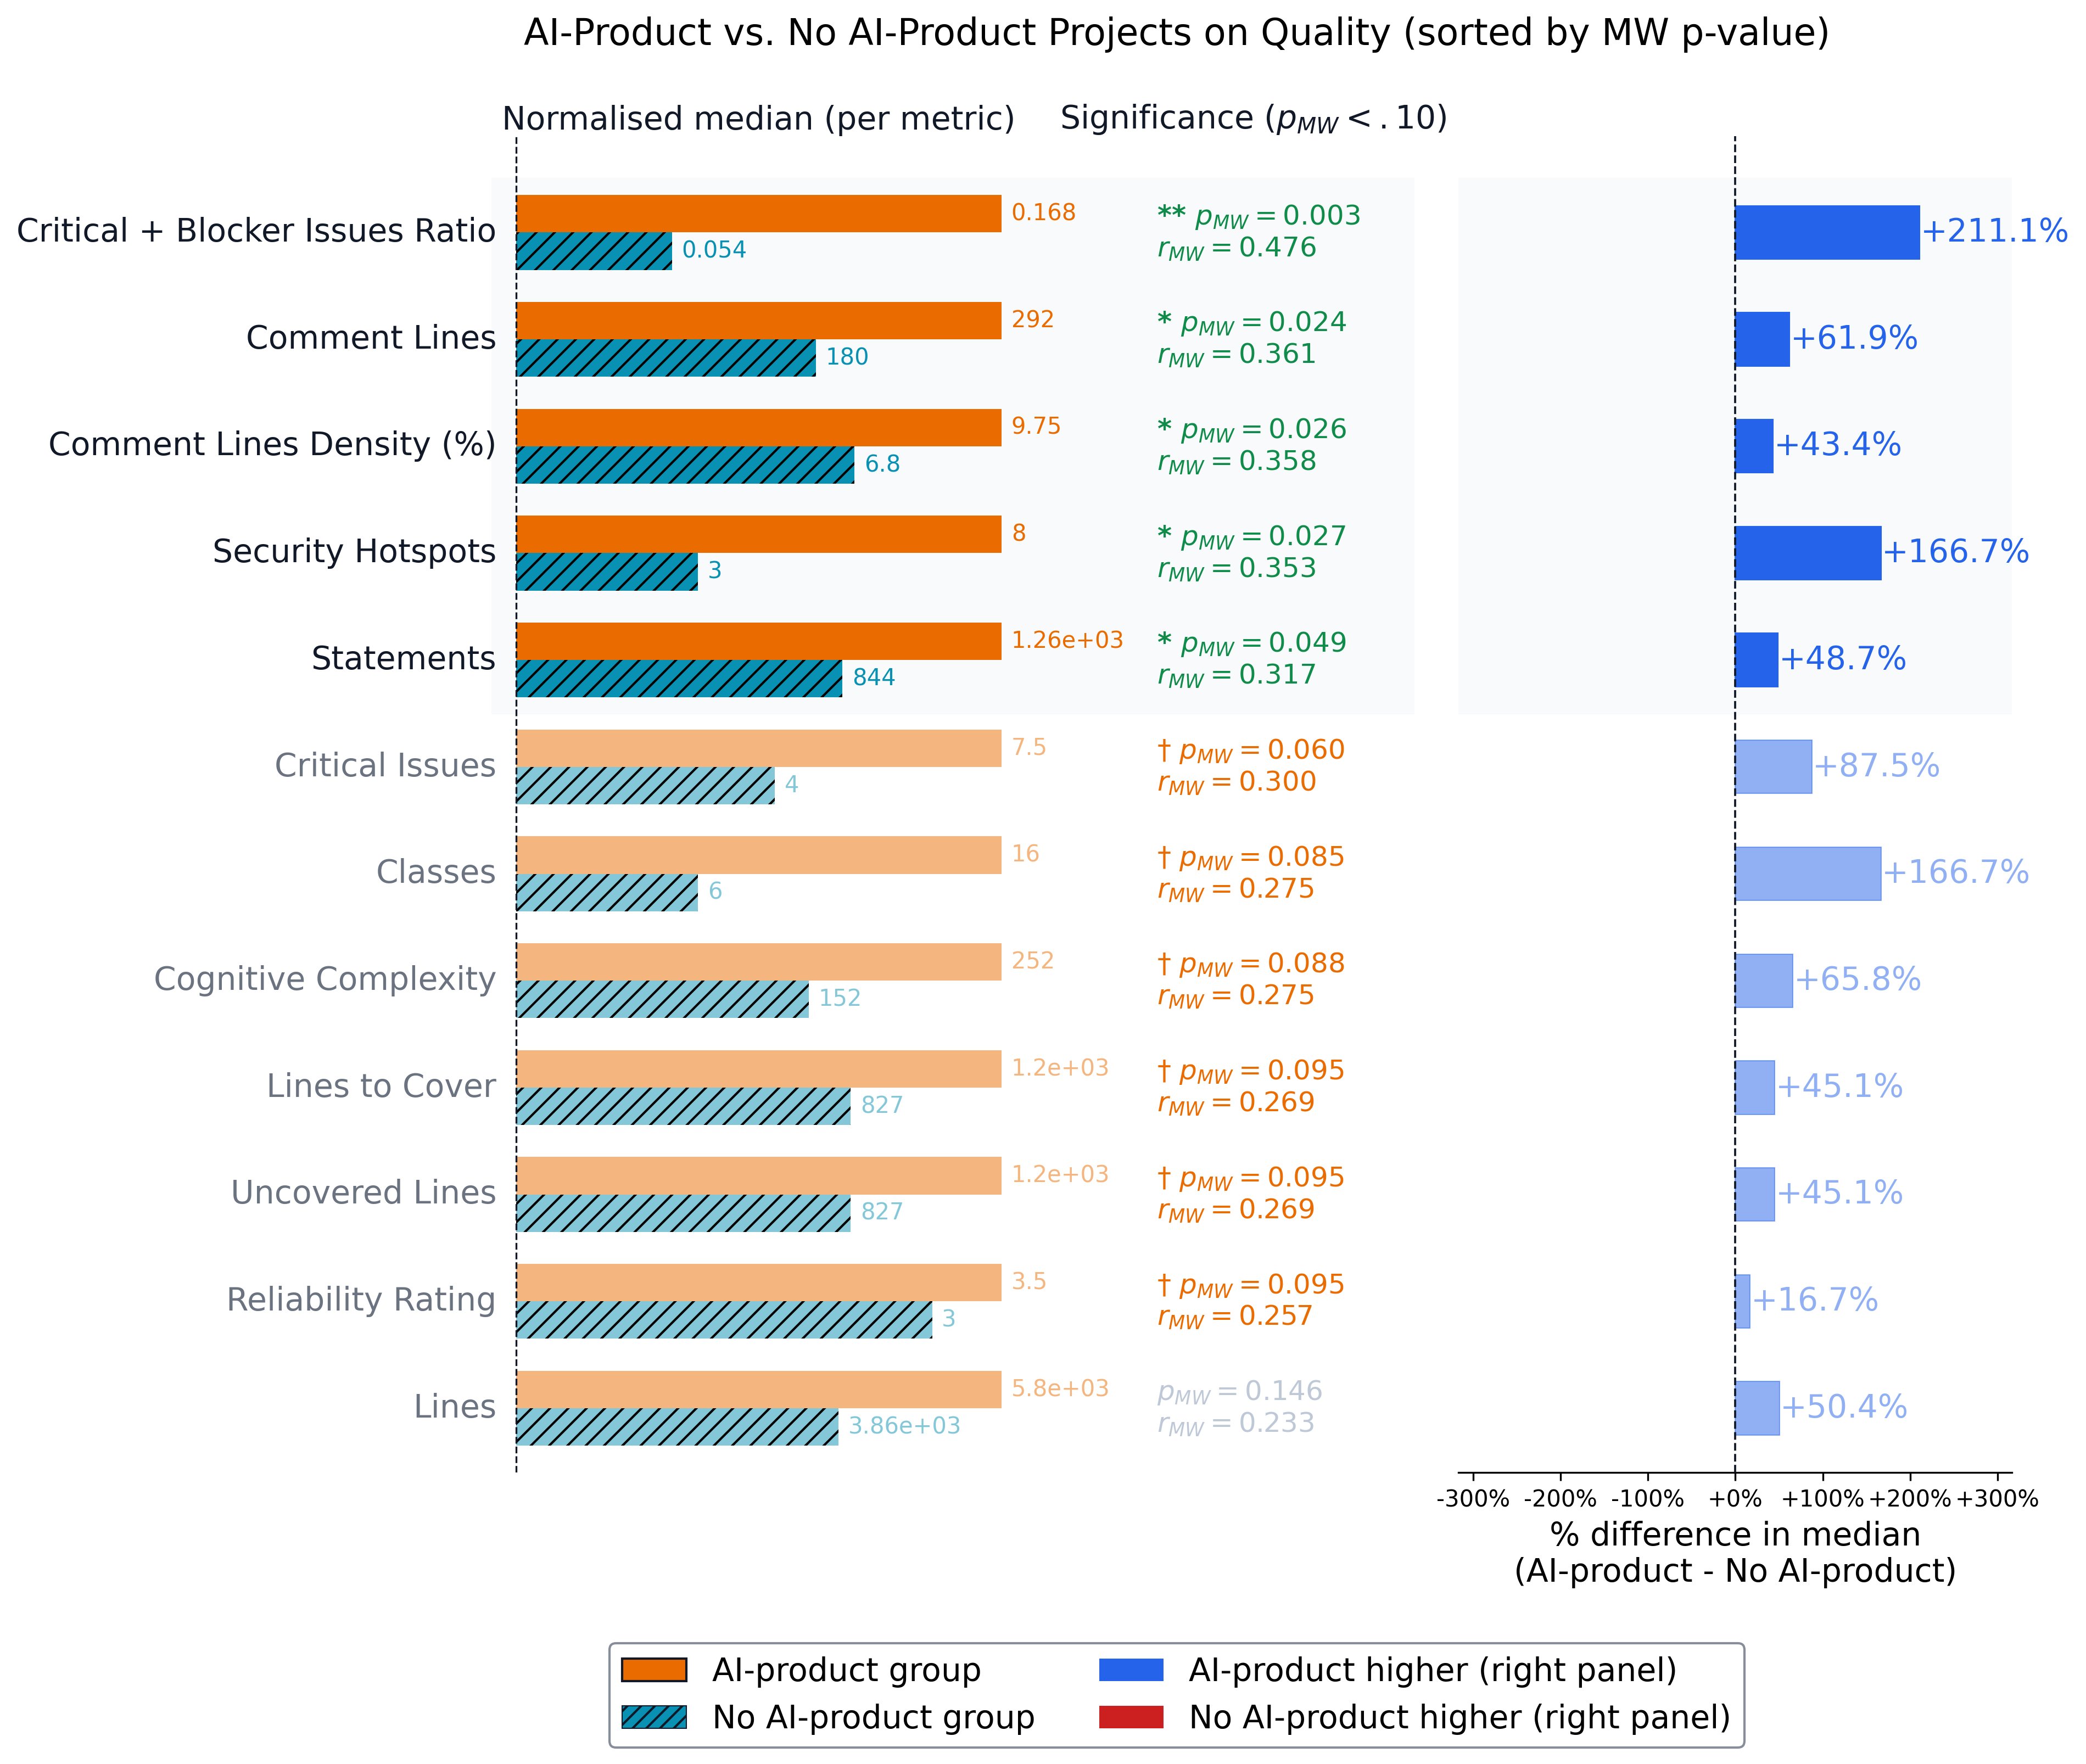

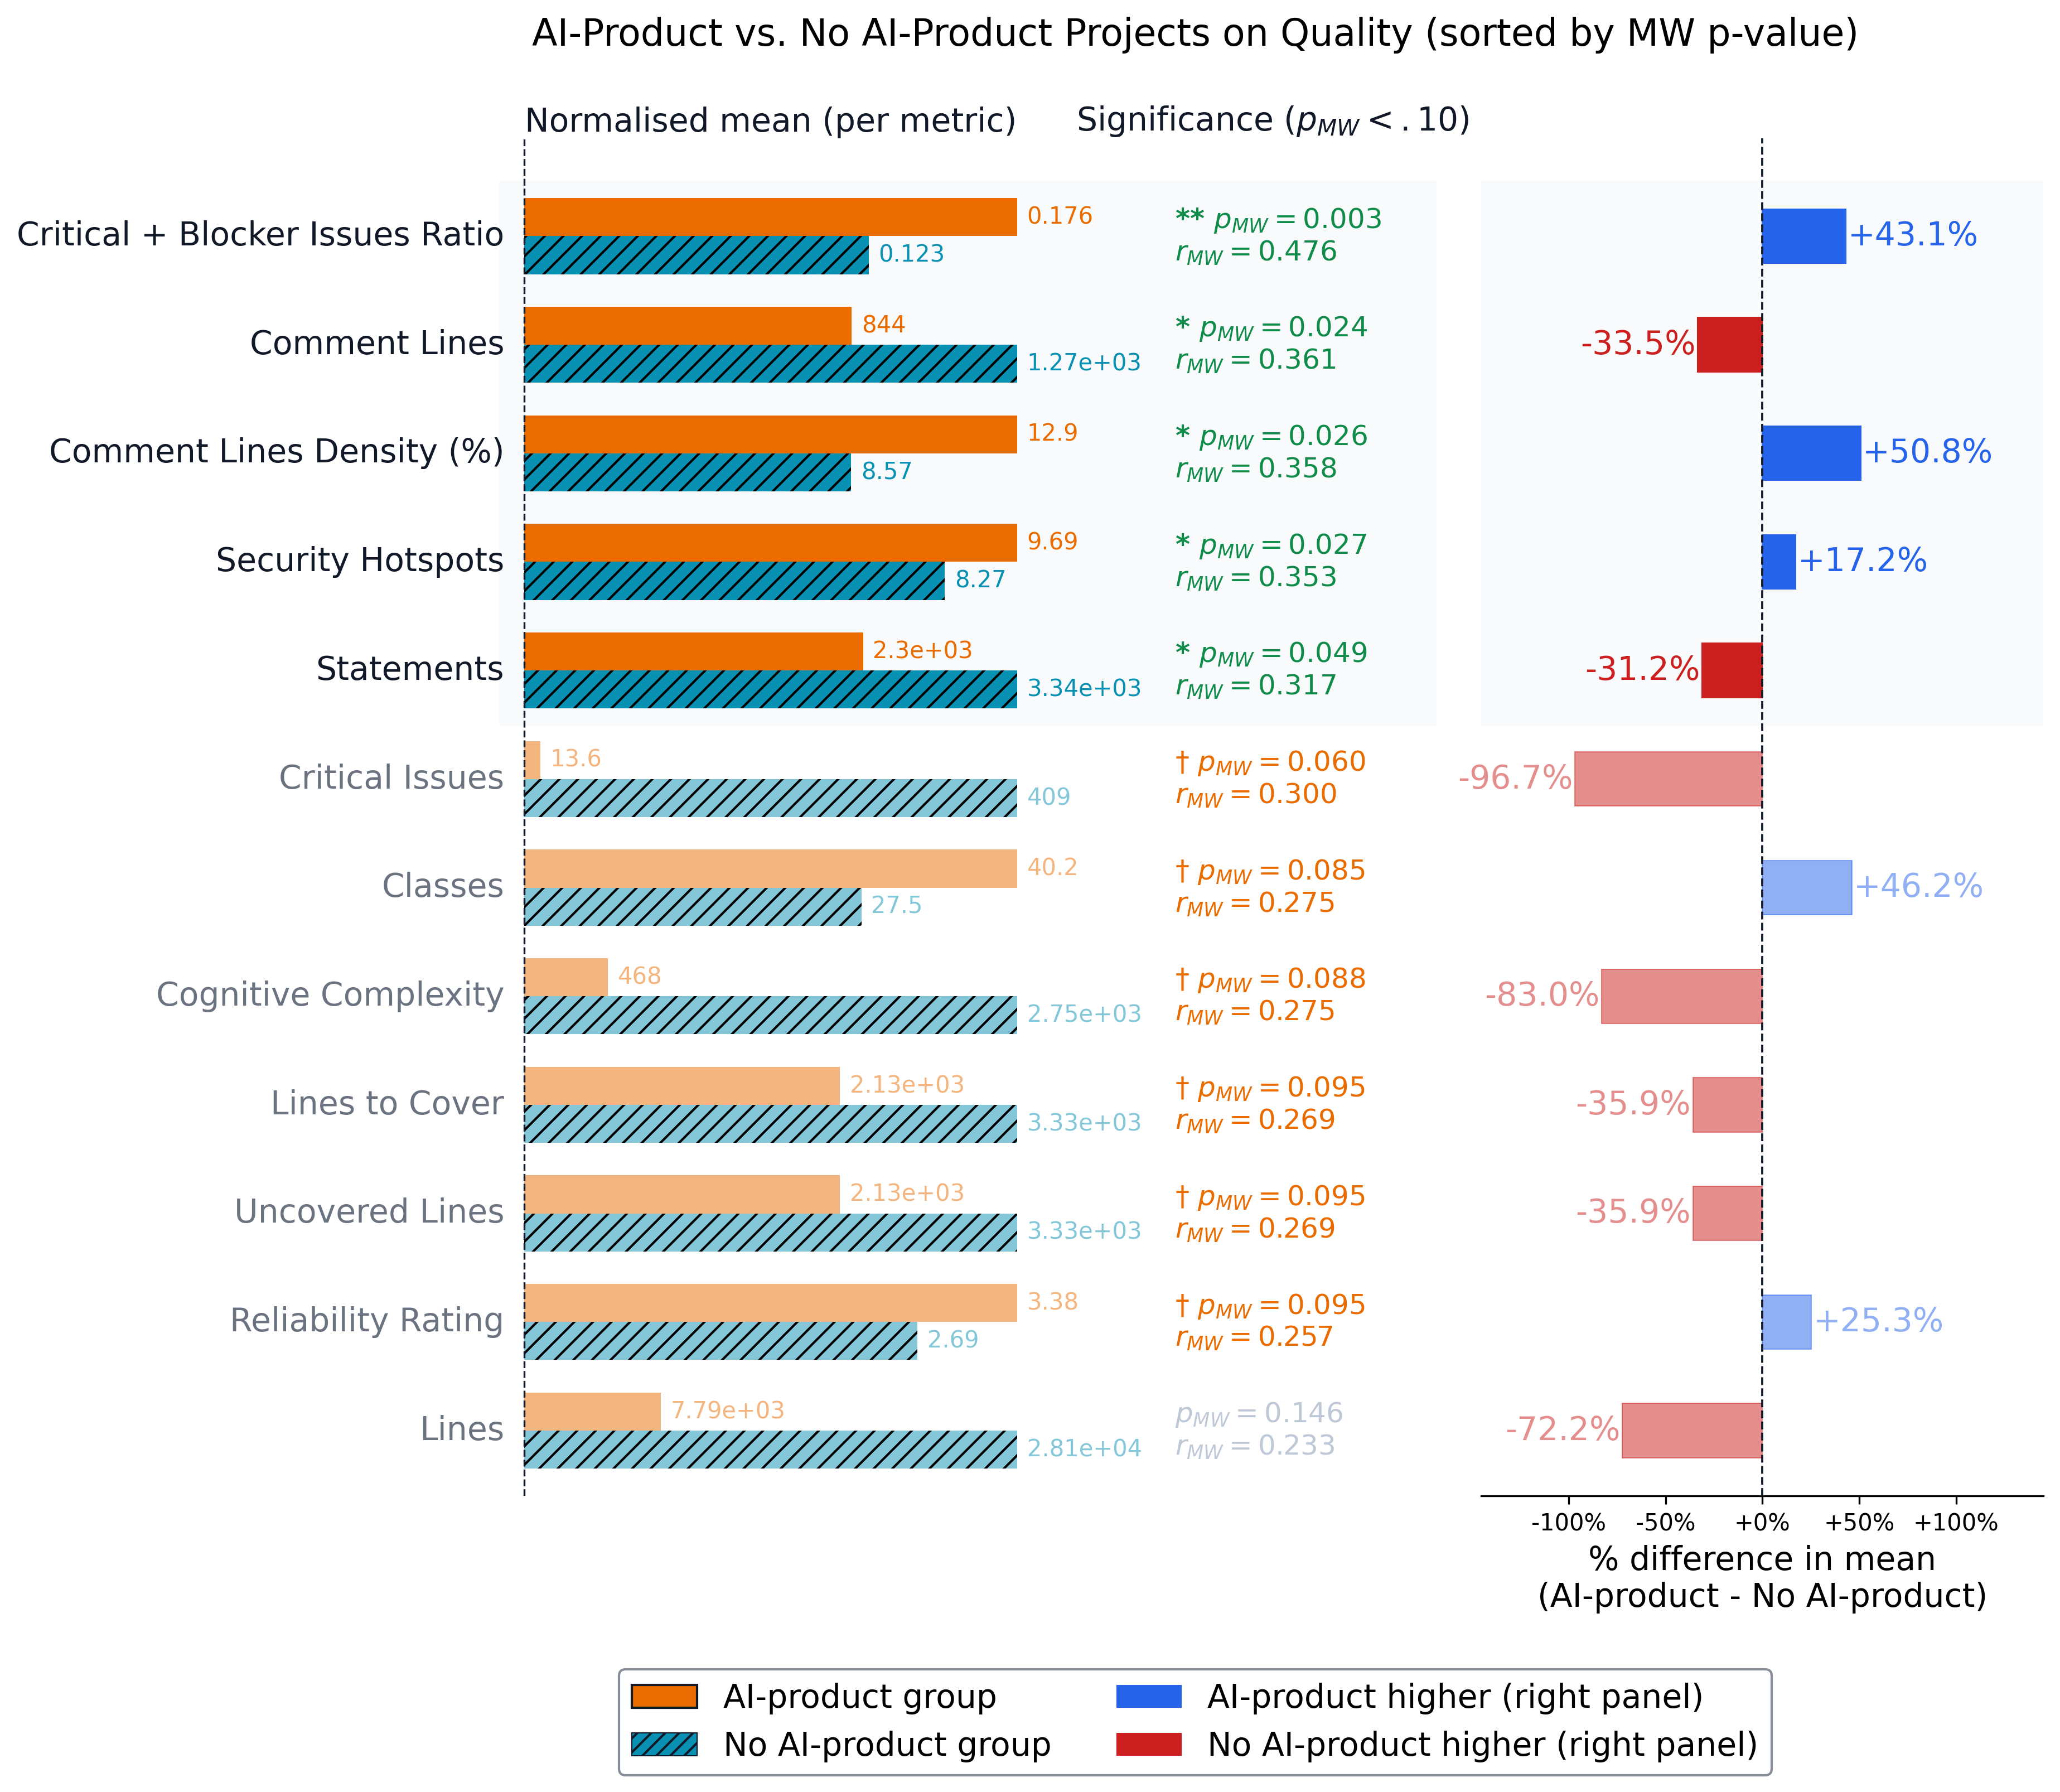

In [57]:
additional = ["lines"]

combined = set(significant_columns) | set(additional)
analysis_df = analysis_df[analysis_df["metric"].isin(combined)]

display(analysis_df)
visualize_mw_results(analysis_df, measure="median", save_path="overleaf/H2_1.pdf")
visualize_mw_results(analysis_df, measure="mean")

In [58]:
metrics = list(analysis_df["metric"])
print(metrics)

to_analyse = repo_df["comment_lines_density"]
display(to_analyse.agg(["mean", "median", "std", "min", "max"]))

['classes', 'cognitive_complexity', 'comment_lines', 'comment_lines_density', 'lines', 'lines_to_cover', 'reliability_rating', 'security_hotspots', 'statements', 'uncovered_lines', 'n_critical', 'critical_plus_blocker_ratio']


mean       9.337363
median     7.100000
std        8.393075
min        0.000000
max       35.200000
Name: comment_lines_density, dtype: float64

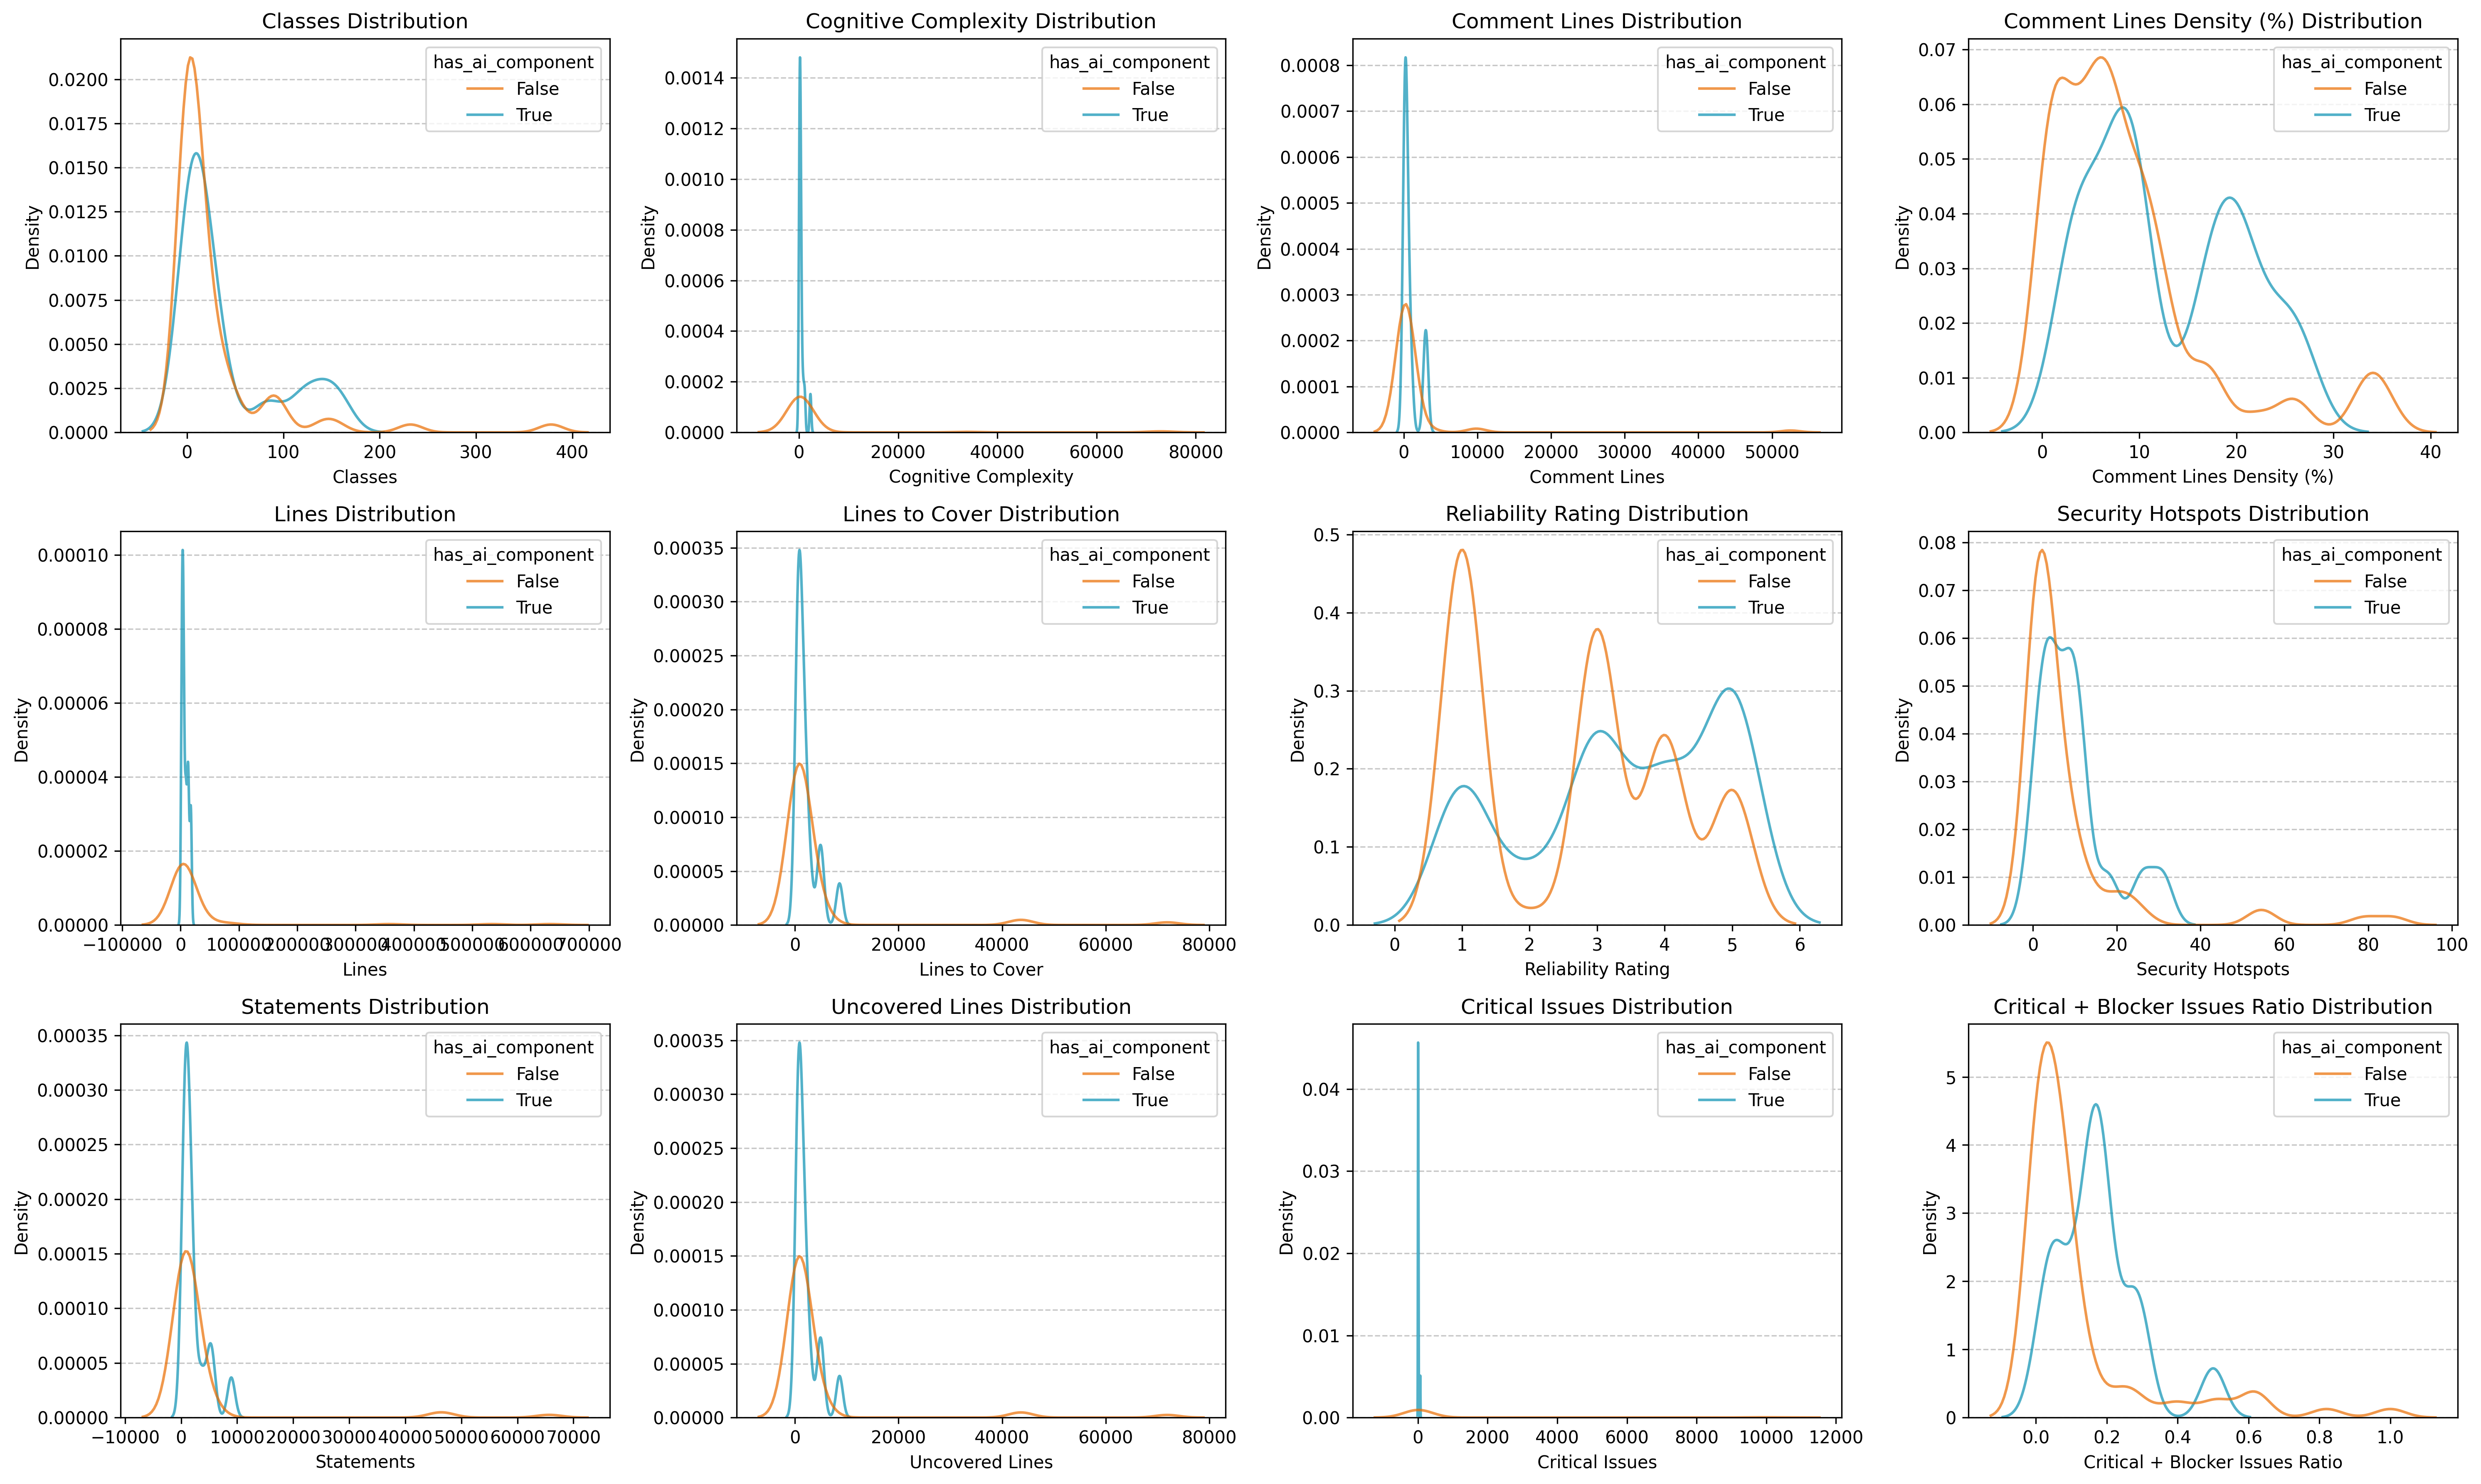

In [59]:
import math

n = len(metrics)

cols = 4  # adjust as you like
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 4), dpi=300)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]

    sns.kdeplot(
        data=repo_df,
        x=metric,
        hue="has_ai_component",
        palette=[C_ORANGE, C_TEAL],
        fill=False,
        common_norm=False,
        alpha=0.7,
        bw_adjust=0.5,
        ax=ax,
    )

    ax.set_title(f"{_label(metric)} Distribution")
    ax.set_xlabel(_label(metric))
    ax.set_ylabel("Density")
    ax.grid(axis="y", linestyle="--", alpha=0.7)

# Remove any empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [60]:
# printable_df = analysis_df.copy()
# printable_df["metric"] = printable_df["metric"].map(lambda m: METRIC_LABELS.get(m, m.replace("_", " ").title()))

# FEATURES_LABELS = {
#     "mean_quality(ai_product)": "Mean (AI)",
#     "median_quality(ai_product)": "Median (AI)",
#     "mean_quality(no_ai_product)": "Mean (No AI)",
#     "median_quality(no_ai_product)": "Median (No AI)",
#     "U(quality|ai_product)": "$U_{AI}$",
#     "U(quality|no_ai_product)": "$U_{No AI}$",
#     "p_mw(quality|ai_product)": "$p_{MW}$",
#     "r_mw(contribution|ai_group)": "$r_{MW}$",
# }
    
# ADDITIONAL_LABELS = {
#     "r_spearman(quality~ai_count)": "$r_{Spearman}$",
#     "p_spearman(quality~ai_count)": "$p_{Spearman}$",
#     "Normal?": "Normally Distributed?"
# }

# FEATURES_ORDERING = [
#     "mean_quality(no_ai_product)", "median_quality(no_ai_product)", "U(quality|no_ai_product)",
#     "mean_quality(ai_product)", "median_quality(ai_product)", "U(quality|ai_product)",
#     "p_mw(quality|ai_product)", "r_mw(contribution|ai_group)",
#     "r_spearman(quality~ai_count)", "p_spearman(quality~ai_count)",
#     "Normal?"
# ]

# features_to_keep = ["metric"] + list(FEATURES_LABELS.keys())

# printable_df = printable_df[features_to_keep]
# printable_df = printable_df.rename(columns=FEATURES_LABELS)

# # Sort by p-value
# printable_df = printable_df.sort_values("p_{MW}")

# ordered_columns = ["metric"] + [FEATURES_LABELS.get(f, f) for f in FEATURES_ORDERING if f in FEATURES_LABELS]
# printable_df = printable_df[ordered_columns]

# print(
#     printable_df
#     .to_latex(index=False, float_format="%.3f")
# )

In [61]:
print(len(df.columns))
# visualize_mw_results(df)

12


In [62]:
# ── Universal colour palette ──────────────────────────────────────────────────
# All colours tested for mutual harmony and sufficient contrast on white/light bg

# Group / category colours
C_AI        = "#2563EB"   # blue        – AI-product group
C_DEV       = "#575B64"   # slate grey  – no AI-product group
C_ORANGE    = "#EA6C00"   # orange      – third category / accent
C_GREEN     = "#0F8C4A"   # green       – fourth category
C_RED       = "#CC1F1F"   # red         – fifth category
C_PURPLE    = "#6D28D9"   # violet      – sixth category
C_TEAL      = "#0891B2"   # teal        – seventh category

# A ready-made ordered list for cycling through groups
CATEGORY_COLORS = [C_AI, C_ORANGE, C_GREEN, C_RED, C_PURPLE, C_TEAL, C_DEV]

# Significance / annotation colours
C_SIG       = "#0F8C4A"   # green  – statistically significant  (matches C_GREEN)
C_TREND     = "#EA6C00"   # amber  – trending                   (matches C_ORANGE)
C_NS        = "#BFC8D7"   # light grey – not significant

# Direction colours (right-panel bars)
C_POS       = "#2563EB"   # blue – AI group higher              (matches C_AI)
C_NEG       = "#CC1F1F"   # red  – no-AI group higher           (matches C_RED)

# Text colours
C_TEXT      = "#111827"   # near-black – significant rows / primary labels
C_TEXT_NS   = "#6B7280"   # mid grey   – non-significant rows
C_TEXT_SOFT = "#9CA3AF"   # light grey – annotations / secondary labels

# Row / background shading
C_ROW_SIG   = "#F0FDF4"   # very light green – significant row highlight
C_ROW_TREND = "#FFF7ED"   # very light amber – trending row highlight
C_ROW_ALT   = "#F9FAFB"   # off-white        – alternating row stripe
C_ROW       = "#FFFFFF"   # white            – default row
C_ROW_SHADING = "#F9FAFB"  # light grey for alternating row shading

# Hatch patterns paired with CATEGORY_COLORS for B&W printing
CATEGORY_HATCHES = ["", "///", "...", "xxx", "\\\\\\", "|||", "+++"]

In [63]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import matplotlib.gridspec as gridspec
# from matplotlib.lines import Line2D

# def _label(m):
#     return METRIC_LABELS.get(m, m.replace("_", " ").title())
 
# def _fmt_p(p):
#     if np.isnan(p):
#         return "p=NA"
#     elif p < 0.001:
#         return "p<0.001"
#     else:
#         return f"p={p:.3f}"

# def _stars(p):
#     if p < 0.001: return "***"
#     if p < 0.01:  return "**"
#     if p < 0.05:  return "*"
#     if p < 0.10:  return "†"
#     return ""
 
# def visualize_ai_component_trends(df, metrics, max_components=5, figsize_scale=1.0):
#     """
#     Visualize code-quality metrics vs. AI-component count.

#     Left panel — sparkline per metric (median trend across AI-component levels).
#     Right panel — horizontal bar showing Spearman correlation (ρ) with AI-component count,
#                   colored by significance.
#     """
#     # ── 1. Aggregate per repository ──────────────────────────────────────────
#     agg_cols = {m: (m, "mean") for m in metrics}
#     agg_cols["ai_component_count"] = ("ai_component_count", "max")
#     repo_df = df.groupby("repository_id").agg(**agg_cols).reset_index()
#     repo_df["ai_level"] = repo_df["ai_component_count"].clip(upper=max_components)

#     # ── 2. Compute median trends ─────────────────────────────────────────────
#     trend = repo_df.groupby("ai_level")[metrics].median().reset_index()
#     levels = sorted(trend["ai_level"].unique())
#     n_levels = len(levels)

#     # ── 3. Compute Spearman correlation ρ and p ─────────────────────────────
#     spearman_rho = {}
#     spearman_p   = {}
#     for m in metrics:
#         valid = repo_df[["ai_component_count", m]].dropna()
#         if len(valid) >= 3:
#             rho, p = stats.spearmanr(valid["ai_component_count"], valid[m])
#             spearman_rho[m] = rho
#             spearman_p[m] = p
#         else:
#             spearman_rho[m] = np.nan
#             spearman_p[m] = np.nan

#     metrics = sorted(metrics, key=lambda m: abs(spearman_p[m]) if not np.isnan(spearman_p[m]) else -1)

#     # ── 4. Figure layout ─────────────────────────────────────────────────────
#     N = len(metrics)
#     ROW_H = 0.55 * figsize_scale
#     TOP_PAD = 1.0 * figsize_scale
#     BOT_PAD = 0.8 * figsize_scale
#     fig_h = N * ROW_H + TOP_PAD + BOT_PAD
#     fig_w = 13 * figsize_scale

#     fig = plt.figure(figsize=(fig_w, fig_h), facecolor=C_ROW, dpi=300)
#     gs = gridspec.GridSpec(
#         N + 1, 3,
#         figure=fig,
#         width_ratios=[2.2, 4.5, 2.0],
#         hspace=0.0, wspace=0.04,
#         left=0.01, right=0.99,
#         top=1 - TOP_PAD / fig_h, bottom=BOT_PAD / fig_h,
#     )

#     alpha = 1.0 if spearman_p[m] < 0.05 else 0.8
    
#     # ── Column headers ───────────────────────────────────────────────────────
#     ax_hdr_lbl   = fig.add_subplot(gs[0, 0])
#     ax_hdr_spark = fig.add_subplot(gs[0, 1])
#     ax_hdr_pct   = fig.add_subplot(gs[0, 2])
#     for ax in (ax_hdr_lbl, ax_hdr_spark, ax_hdr_pct):
#         ax.set_facecolor(C_ROW)
#         ax.axis("off")
#         ax.set_alpha(alpha)

#     xs_norm = np.linspace(0.05, 0.95, n_levels)
#     for x, lvl in zip(xs_norm, levels):
#         label = f"≥{int(lvl)}" if lvl == max_components else str(int(lvl))
#         ax_hdr_spark.text(x, 0.1, label, ha="center", va="bottom", fontsize=8, color=C_TEXT, transform=ax_hdr_spark.transAxes)
#     ax_hdr_spark.text(0.5, 0.85, f"AI components  (0 → {max_components}+)", ha="center", va="top", fontsize=8, color=C_TEXT, transform=ax_hdr_spark.transAxes)
#     ax_hdr_pct.text(0.5, 0.5, "Spearman ρ (rho) and p between \n AI component count and quality metric", ha="center", va="center", fontsize=8, color=C_TEXT, transform=ax_hdr_pct.transAxes)

#     # ── 5. Metric rows ──────────────────────────────────────────────────────
#     for i, m in enumerate(metrics):
#         row_idx = i + 1
#         bg = C_ROW_SHADING if i % 2 == 0 else C_ROW

#         ax_lbl   = fig.add_subplot(gs[row_idx, 0])
#         ax_spark = fig.add_subplot(gs[row_idx, 1])
#         ax_pct   = fig.add_subplot(gs[row_idx, 2])

#         for ax in (ax_lbl, ax_spark, ax_pct):
#             ax.set_facecolor(bg)
#             ax.axis("off")

#         # Label
#         ax_lbl.text(0.97, 0.5, _label(m), ha="right", va="center", fontsize=9, color=C_TEXT, transform=ax_lbl.transAxes)

#         # Sparkline        
#         vals = [float(trend.loc[trend["ai_level"] == lvl, m].values[0]) if len(trend.loc[trend["ai_level"] == lvl, m]) else np.nan for lvl in levels]
#         valid = [v for v in vals if not np.isnan(v)]
#         lo, hi = (min(valid), max(valid)) if valid else (0, 1)
#         span = hi - lo if hi != lo else 1.0
#         norm = [0.15 + 0.7 * (v - lo) / span if not np.isnan(v) else np.nan for v in vals]

#         valid_x = [x for x, n in zip(xs_norm, norm) if not np.isnan(n)]
#         valid_n = [n for n in norm if not np.isnan(n)]
#         if len(valid_x) > 1:
#             ax_spark.plot(valid_x, valid_n, color=C_AI, lw=1.8, solid_capstyle="round", transform=ax_spark.transAxes, zorder=2)
#         for x, n, v in zip(xs_norm, norm, vals):
#             if np.isnan(n): continue
#             ax_spark.scatter(x, n, s=38, color=C_AI, edgecolors=C_DEV, linewidths=0.8, transform=ax_spark.transAxes, zorder=3)
#             va, dy = ("bottom", 0.10) if n < 0.7 else ("top", -0.10)
#             fmt = f"{v:.2g}" if abs(v) < 1000 else f"{v/1000:.1f}k"
#             ax_spark.text(x, n + dy, fmt, ha="center", va=va, fontsize=7, color=C_DEV, transform=ax_spark.transAxes, zorder=4)
#         ax_spark.axhline(0.5, xmin=0.03, xmax=0.97, color=C_DEV, lw=0.6, zorder=1)

#         # Spearman % bar with significance shading
#         rho, p = spearman_rho[m], spearman_p[m]
#         if not np.isnan(rho):
#             bar_color = C_POS if rho >= 0 else C_NEG
#             if p >= 0.1:
#                 bar_color = C_NS
#             elif p < 0.05:
#                 bar_color = C_SIG
#             elif p < 0.1:
#                 bar_color = C_TREND
#             bar_len = abs(rho)
#             x0 = 0.5
#             left = x0 if rho >= 0 else x0 - bar_len * 0.45
#             ax_pct.barh(0.5, bar_len * 0.45, left=left, height=0.55, color=bar_color, transform=ax_pct.transAxes, zorder=2)

#             # p-value overlay (thin strip)
#             if not np.isnan(p):
#                 p_strength = 1 - min(p, 1.0)
#                 ax_pct.barh(0.5, p_strength * 0.9, left=0.05, height=0.18, color=C_SIG, alpha=0.15, transform=ax_pct.transAxes, zorder=1)

#             txt = f"{_stars(p)} {_fmt_p(p)}\nρ (rho)={rho:.2f}"
#             ha = "left" if rho >= 0 else "right"
#             xpos = x0 + bar_len * 0.45 + 0.04 if rho >= 0 else x0 - bar_len * 0.45 - 0.04
#             ax_pct.text(
#                 xpos,
#                 0.5, 
#                 txt, 
#                 ha=ha, 
#                 va="center", 
#                 fontsize=8 if p < alpha else 7.5, 
#                 fontweight="bold" if p < alpha else "normal",
#                 color=bar_color, 
#                 transform=ax_pct.transAxes
#             )

#         ax_pct.axvline(0.5, color=C_SIG, lw=0.8, zorder=0)

#     # ── 6. Title + legend ────────────────────────────────────────────────────
#     fig.suptitle("Code quality vs. AI component count from 1 to 5, sorted by Spearman p value", fontsize=11, color=C_TEXT, y=1 - 0.18 / fig_h, ha="center")
#     legend_elements = [
#         Line2D([0],[0], color=C_AI,  lw=2, label="Trendline of mean values across AI component levels"),
#         Line2D([0],[0], color=C_SIG, lw=4, label="Significant (p<0.05)"),
#         Line2D([0],[0], color=C_TREND, lw=4, label="Trending (0.05 ≤ p < 0.1)"),
#         Line2D([0],[0], color=C_NS, lw=4, label="Not significant (p ≥ 0.1)"),
#     ]
#     fig.legend(handles=legend_elements, loc="lower center", ncol=4, fontsize=8, frameon=False, labelcolor=C_DEV, bbox_to_anchor=(0.55, 0.005))

#     plt.show()
    
#     return repo_df, trend, spearman_rho, spearman_p

In [64]:
from matplotlib.patches import Patch
from scipy import stats
from matplotlib import gridspec

def _label(m):
    return METRIC_LABELS.get(m, m.replace("_", " ").title())
 
def _fmt_p(p):
    if np.isnan(p):
        return "p=NA"
    elif p < 0.001:
        return "p<0.001"
    else:
        return f"p={p:.3f}"

def _stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    if p < 0.10:  return "†"
    return ""

def visualize_ai_component_trends(df, max_components=5, figsize_scale=1.0, save_path=None):
    repo_df = df.copy()
    repo_df["ai_level"] = repo_df["ai_component_count"].clip(upper=max_components).astype(int)
    levels = sorted(repo_df["ai_level"].unique())

    metrics = quality_metrics

    # ── 2. Spearman on raw per-repo values ────────────────────────────────
    spearman_rho, spearman_p = {}, {}
    for m in metrics:
        valid = repo_df[["ai_component_count", m]].dropna()
        if len(valid) >= 3:
            rho, p = stats.spearmanr(valid["ai_component_count"], valid[m])
            spearman_rho[m] = rho
            spearman_p[m]   = p
        else:
            spearman_rho[m] = np.nan
            spearman_p[m]   = np.nan

    metrics = sorted(metrics, key=lambda m: spearman_p[m] if not np.isnan(spearman_p[m]) else 1.0)
    filtered_metrics = [m for m in metrics if not np.isnan(spearman_p[m]) and spearman_p[m] < 0.10]

    # ── 3. Figure layout ──────────────────────────────────────────────────
    N       = len(filtered_metrics)
    ROW_H   = 1.4 * figsize_scale          # was 1.1 — more vertical space per row
    TOP_PAD = 1.2 * figsize_scale
    BOT_PAD = 1.8 * figsize_scale          # extra room for shared xlabels + legend
    fig_h   = N * ROW_H + TOP_PAD + BOT_PAD
    fig_w   = 14 * figsize_scale

    fig = plt.figure(figsize=(fig_w, fig_h), facecolor=C_ROW, dpi=300)

    # Use a header row that's shorter than data rows
    height_ratios = [0.4] + [1.0] * N
    gs = gridspec.GridSpec(
        N + 1, 3,
        figure=fig,
        width_ratios=[1.4, 5.5, 2.2],
        height_ratios=height_ratios,
        hspace=0.55,                       # WAS 0.0 — main fix for row overlap
        wspace=0.04,
        left=0.18, right=0.97,
        top=1 - TOP_PAD / fig_h,
        bottom=BOT_PAD / fig_h,
    )

    level_colors = {lvl: CATEGORY_COLORS[i % len(CATEGORY_COLORS)] for i, lvl in enumerate(levels)}

    # ── 4. Column headers ─────────────────────────────────────────────────
    ax_hdr_lbl = fig.add_subplot(gs[0, 0])
    ax_hdr_box = fig.add_subplot(gs[0, 1])
    ax_hdr_rho = fig.add_subplot(gs[0, 2])
    for ax in (ax_hdr_lbl, ax_hdr_box, ax_hdr_rho):
        ax.set_facecolor(C_ROW)
        ax.axis("off")

    ax_hdr_box.text(0.5, 0.5,
                    f"Distribution per AI component level (0 → {max_components})",
                    ha="center", va="center", fontsize=14, color=C_TEXT,
                    transform=ax_hdr_box.transAxes)
    ax_hdr_rho.text(0.5, 0.5,
                    "Spearman $\\rho$\n(component count vs. metric)",
                    ha="center", va="center", fontsize=14, color=C_TEXT,
                    transform=ax_hdr_rho.transAxes)

    # ── 5. Metric rows ────────────────────────────────────────────────────
    for i, m in enumerate(filtered_metrics):
        row_idx = i + 1
        p   = spearman_p[m]
        rho = spearman_rho[m]
        is_last_row = (i == N - 1)

        if not np.isnan(p) and p < 0.05:
            bg = C_ROW_SIG
        elif not np.isnan(p) and p < 0.10:
            bg = C_ROW_TREND
        elif i % 2 == 0:
            bg = C_ROW_ALT
        else:
            bg = C_ROW

        ax_lbl = fig.add_subplot(gs[row_idx, 0])
        ax_box = fig.add_subplot(gs[row_idx, 1])
        ax_rho = fig.add_subplot(gs[row_idx, 2])

        for ax in (ax_lbl, ax_box, ax_rho):
            ax.set_facecolor(bg)

        ax_lbl.axis("off")

        # ── Label ─────────────────────────────────────────────────────────
        ax_lbl.text(0.97, 0.5, _label(m),
                    ha="right", va="center", fontsize=14,
                    color=C_TEXT if (not np.isnan(p) and p < 0.05) else C_TEXT_NS,
                    transform=ax_lbl.transAxes)

        # ── Boxplot per AI level ──────────────────────────────────────────
        col_data = repo_df[m].dropna()
        Q1, Q3   = col_data.quantile(0.25), col_data.quantile(0.75)
        IQR      = Q3 - Q1
        x_min    = Q1 - 1.5 * IQR
        x_max    = Q3 + 1.5 * IQR

        box_data, box_labels, box_colors = [], [], []
        for lvl in levels:
            subset = repo_df.loc[repo_df["ai_level"] == lvl, m].dropna()
            subset = subset[(subset >= x_min) & (subset <= x_max)]
            if len(subset) == 0:
                continue
            box_data.append(subset.values)
            box_labels.append(f"{int(lvl)}" if lvl == max_components else str(int(lvl)))
            box_colors.append(level_colors[lvl])

        if box_data:
            bp = ax_box.boxplot(
                box_data, vert=False, patch_artist=True,
                tick_labels=box_labels, widths=0.5,
                flierprops=dict(marker="o", markersize=2, linestyle="none",
                                markeredgewidth=0.5, alpha=0.5),
                medianprops=dict(color=C_TEXT, linewidth=1.5),
                whiskerprops=dict(linewidth=0.8, color=C_TEXT_NS),
                capprops=dict(linewidth=0.8, color=C_TEXT_NS),
                boxprops=dict(linewidth=0.6),
            )
            for patch, color in zip(bp["boxes"], box_colors):
                patch.set_facecolor(color)
                patch.set_alpha(0.55)
            for flier, color in zip(bp["fliers"], box_colors):
                flier.set_markerfacecolor(color)
                flier.set_markeredgecolor(color)

        ax_box.set_xlim(x_min, x_max)
        # NO xlabel on every row — metric name is already shown in the label column
        ax_box.tick_params(axis="x", labelsize=11, colors=C_TEXT_NS, length=2, pad=2)
        ax_box.tick_params(axis="y", labelsize=12, colors=C_TEXT_NS, length=0)
        for spine in ("top", "right"):
            ax_box.spines[spine].set_visible(False)
        ax_box.spines["bottom"].set_color(C_TEXT_NS)
        ax_box.spines["bottom"].set_linewidth(0.5)
        ax_box.spines["left"].set_color(C_TEXT_NS)
        ax_box.spines["left"].set_linewidth(0.5)

        # ── Spearman ρ bar ────────────────────────────────────────────────
        if not np.isnan(rho):
            if np.isnan(p) or p >= 0.10:
                bar_color = C_NS
            elif p < 0.05:
                bar_color = C_SIG
            else:
                bar_color = C_TREND

            ax_rho.barh(0.5, rho, left=0, height=0.5,
                        color=bar_color, zorder=2)

            ha   = "left" if rho >= 0 else "right"
            xpos = rho + (0.05 if rho >= 0 else -0.05)
            txt  = f"{_stars(p)} {_fmt_p(p)}\nρ={rho:.3f}"
            ax_rho.text(xpos, 0.5, txt,
                        ha=ha, va="center", fontsize=12,
                        fontweight="bold" if (not np.isnan(p) and p < 0.05) else "normal",
                        color=bar_color)

        ax_rho.axvline(0, color=C_TEXT_NS, lw=0.8, zorder=3)
        ax_rho.set_xlim(-1, 1)
        ax_rho.set_ylim(0, 1)
        ax_rho.set_xticks([-1, -0.5, 0, 0.5, 1])

        # Only show x-axis tick labels on the LAST row
        if is_last_row:
            ax_rho.set_xticklabels(["-1", "-.5", "0", ".5", "1"],
                                    fontsize=12, color=C_TEXT_NS)
            ax_rho.tick_params(axis="x", length=2, pad=2)
        else:
            ax_rho.set_xticklabels([])
            ax_rho.tick_params(axis="x", length=2)

        ax_rho.tick_params(axis="y", left=False, labelleft=False)
        for spine in ("top", "right", "left"):
            ax_rho.spines[spine].set_visible(False)
        ax_rho.spines["bottom"].set_color(C_TEXT_NS)
        ax_rho.spines["bottom"].set_linewidth(0.5)

    # ── 6. Legend + title ─────────────────────────────────────────────────
    legend_elements = (
        [Patch(facecolor=c, alpha=0.55, label=f"AI components: {int(lvl)}")
         for lvl, c in level_colors.items()]
        + [
            Patch(facecolor=C_SIG,   label="Significant (p<0.05)"),
            Patch(facecolor=C_TREND, label="Trending (p<0.10)"),
            Patch(facecolor=C_NS,    label="Not significant"),
        ]
    )
    fig.legend(handles=legend_elements, loc="lower center",
               ncol=min(len(legend_elements), 5),
               fontsize=13, frameon=False, labelcolor=C_DEV,
               bbox_to_anchor=(0.55, 0.01))

    fig.suptitle(
        "Code quality vs. AI component count — distribution per level, sorted by Spearman p",
        fontsize=16, color=C_TEXT, y=0.985, x=0.55,
    )

    if save_path:
        plt.savefig(save_path, format="pdf", bbox_inches="tight")

    plt.show()

    # ── Summary stats DF ──────────────────────────────────────────────────
    final_df = []
    for m in metrics:
        col_data = repo_df[m].dropna()
        Q1, Q3   = col_data.quantile(0.25), col_data.quantile(0.75)
        IQR      = Q3 - Q1
        final_df.append({
            "metric": m,
            "mean": col_data.mean(),
            "median": col_data.median(),
            "std": col_data.std(),
            "Q1": Q1, "Q3": Q3, "iqr": IQR,
            "min": col_data.min(),
            "max": col_data.max(),
            "spearman_rho": spearman_rho[m],
            "spearman_p": spearman_p[m],
        })
    final_df = pd.DataFrame(final_df)

    return repo_df, spearman_rho, spearman_p, final_df

/var/folders/_t/r4r1x6jd1c5dgbwllqhbsyrw0000gn/T/ipykernel_92368/4139060902.py:35: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["ai_component_count"], valid[m])


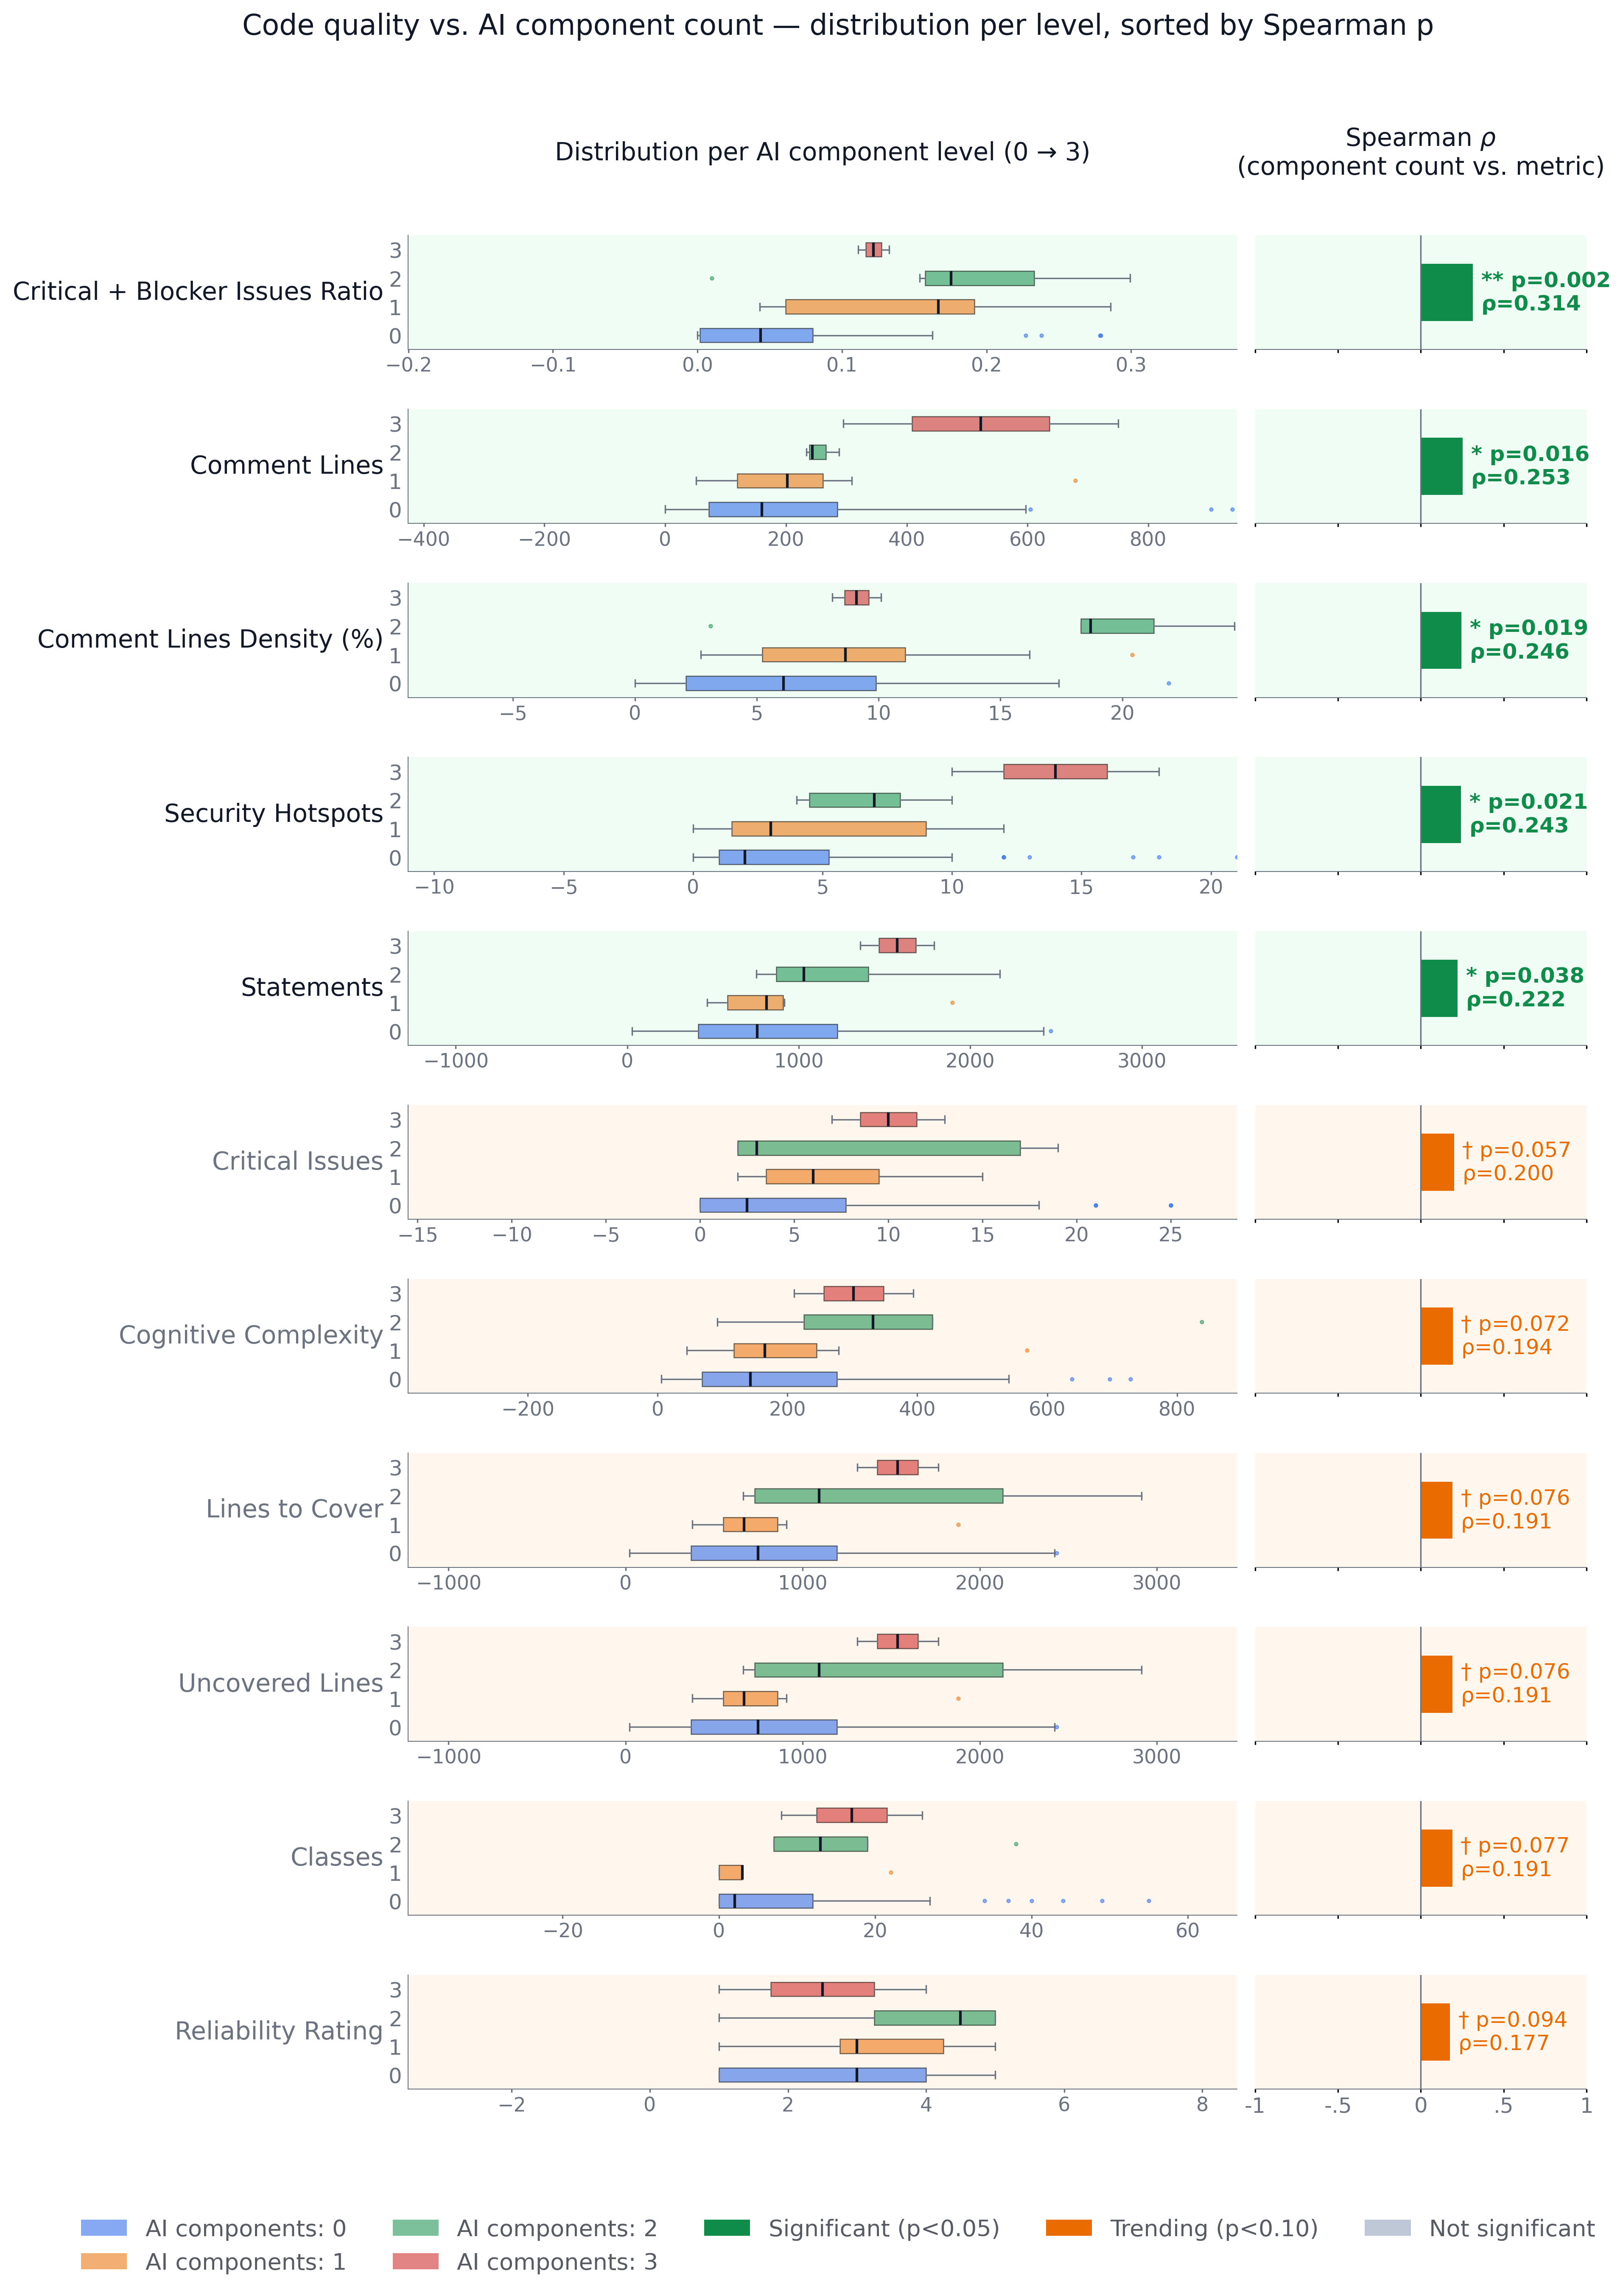

,repository_id,has_ai_component,ai_component_count,bugs,classes,code_smells,cognitive_complexity,comment_lines,comment_lines_density,complexity,...,critical_plus_blocker_ratio,major_ratio,minor_ratio,info_ratio,security_ratio,reliability_ratio,maintainability_ratio,snapshot_commit,date,ai_level
0,2017_KDPRO-SINTEF_BowtieTool,False,0,44845,378.0,115263,33653.0,52507,25.5,28805.0,...,0.064843,0.761906,0.172426,0.000824,0.000006,0.316453,0.720478,69b30a5a551aea56b4cf200f74e6fcf23abe2c1d,2017-11-21 09:33:58+00:00,0
1,2017_egrimstad_scalpel,False,0,6,10.0,138,158.0,511,10.1,511.0,...,0.013889,0.590278,0.381944,0.013889,0.000000,0.437500,0.979167,7a29c5921df33ccdad8f21ac8336c06964740ad8,2017-11-23 11:29:47+00:00,0
2,2018_K-pro-SafeTec_Emergency-Response-CloudFun...,False,0,0,0.0,50,25.0,115,34.5,46.0,...,0.820000,0.020000,0.160000,0.000000,0.000000,0.040000,1.000000,aba72dbf1459c7712bd840543ac9d8fd82f690a1,2018-11-15 12:33:27+00:00,0
3,2018_K-pro-SafeTec_Emergency-Response-Portal,False,0,5,12.0,335,179.0,289,4.1,482.0,...,0.011765,0.841176,0.147059,0.000000,0.000000,0.797059,0.991176,262d941fa61ac42b52439a90aab965e6ac397502,2018-11-15 12:17:06+00:00,0
4,2018_Kpro11_Aqeous,False,0,907,0.0,3405,404.0,2650,10.2,516.0,...,0.073748,0.630798,0.295455,0.000000,0.000000,0.471243,0.788729,78a06ec7166bbbb9bbd0a63cb4eddea5d9054f95,2018-11-27 16:12:20+00:00,0


{'bugs': np.float64(0.9507632483584083),
 'classes': np.float64(0.0766548406134651),
 'code_smells': np.float64(0.7125849201472473),
 'cognitive_complexity': np.float64(0.07241583654404675),
 'comment_lines': np.float64(0.015591833693596763),
 'comment_lines_density': np.float64(0.01873475356565563),
 'complexity': np.float64(0.40408829841103233),
 'coverage': nan,
 'duplicated_blocks': np.float64(0.8390622355572955),
 'duplicated_files': np.float64(0.6321401701758357),
 'duplicated_lines': np.float64(0.35150431213958383),
 'duplicated_lines_density': np.float64(0.26398515778549364),
 'files': np.float64(0.651226042501174),
 'functions': np.float64(0.6100826188812742),
 'lines': np.float64(0.13627572676560856),
 'lines_to_cover': np.float64(0.07611038578587205),
 'ncloc': np.float64(0.44635704288058253),
 'open_issues': np.float64(0.7381765034284639),
 'reliability_rating': np.float64(0.09419269062302955),
 'reliability_remediation_effort': np.float64(0.8036564042372398),
 'security_ho

{'bugs': np.float64(0.00656365072146539),
 'classes': np.float64(0.19082216900127832),
 'code_smells': np.float64(0.039143730035981185),
 'cognitive_complexity': np.float64(0.19357810769880118),
 'comment_lines': np.float64(0.2528710431007482),
 'comment_lines_density': np.float64(0.24602779248823287),
 'complexity': np.float64(0.09057685670885865),
 'coverage': nan,
 'duplicated_blocks': np.float64(0.021585867185435603),
 'duplicated_files': np.float64(0.05085365182922799),
 'duplicated_lines': np.float64(0.09879262064977143),
 'duplicated_lines_density': np.float64(0.1183194251918113),
 'files': np.float64(0.04802525811493141),
 'functions': np.float64(0.055432666172999925),
 'lines': np.float64(0.15737449414240756),
 'lines_to_cover': np.float64(0.19116919069891203),
 'ncloc': np.float64(0.08081360766110042),
 'open_issues': np.float64(0.03552089847838894),
 'reliability_rating': np.float64(0.17650936165046632),
 'reliability_remediation_effort': np.float64(0.026422949752143328),
 '

In [65]:
repo_df, spearman_rho, spearman_p, final_df = visualize_ai_component_trends(bigboy_df, max_components=3, save_path="overleaf/H2_2.pdf")
display(repo_df.head())
display(spearman_p)
display(spearman_rho)

In [66]:
print(final_df.to_latex(index=False, float_format="%.3f"))

\begin{tabular}{lrrrrrrrrrr}
\toprule
metric & mean & median & std & Q1 & Q3 & iqr & min & max & spearman_rho & spearman_p \\
\midrule
critical_plus_blocker_ratio & 0.133 & 0.065 & 0.190 & 0.015 & 0.158 & 0.143 & 0.000 & 1.000 & 0.314 & 0.002 \\
comment_lines & 1194.165 & 225.000 & 5657.054 & 89.000 & 432.000 & 343.000 & 0.000 & 52507.000 & 0.253 & 0.016 \\
comment_lines_density & 9.337 & 7.100 & 8.393 & 3.450 & 11.950 & 8.500 & 0.000 & 35.200 & 0.246 & 0.019 \\
security_hotspots & 8.516 & 3.000 & 14.839 & 1.000 & 9.000 & 8.000 & 0.000 & 86.000 & 0.243 & 0.021 \\
statements & 3146.701 & 891.000 & 9713.116 & 534.500 & 1742.000 & 1207.500 & 27.000 & 65666.000 & 0.222 & 0.038 \\
n_critical & 339.385 & 4.000 & 1780.776 & 1.000 & 12.000 & 11.000 & 0.000 & 10290.000 & 0.200 & 0.057 \\
cognitive_complexity & 2333.230 & 172.000 & 11458.357 & 94.500 & 413.500 & 319.000 & 6.000 & 73461.000 & 0.194 & 0.072 \\
lines_to_cover & 3106.724 & 840.000 & 9924.623 & 527.000 & 1697.000 & 1170.000 & 23.000 